# EDA · RETECO Track 1 (TEMPO) — sub-tracks 1a y 1b

Este notebook ejecuta el [`PLAN_EDA.md`](../PLAN_EDA.md) (análisis de datos) en un solo lugar. **La corrida del baseline (BM25 oficial, densos, comparación con el paper) está en [`baseline_track1_tempo.ipynb`](baseline_track1_tempo.ipynb).**

**Objetivo:** entender el corpus, las consultas, los pasos y los juicios de relevancia de la Tarea 1 para tomar decisiones informadas sobre el pipeline (retriever, reranker y uso del razonamiento temporal).

**Regla de trabajo:** todo el análisis y cualquier decisión de diseño se hace sobre **train**. Dev solo aparece en la sección 1, en comprobaciones de integridad (que los archivos estén bien formados), nunca para medir rendimiento.

| Sección | Contenido |
|---|---|
| 0 | Configuración y cargadores reutilizables |
| 1 | Inventario y estructura (sanity checks) |
| 2 | Corpus (`documents.jsonl`) |
| 3 | Consultas 1a (`examples_*.jsonl`) |
| 4 | Pasos 1b (`steps_*.jsonl`) |
| 5 | Guidance temporal (`guidance_*.jsonl`) |
| 6 | Hallazgos sobre los datos |

> Este notebook **no ejecuta ningún retriever**. Lo que antes estaba aquí y mide rendimiento (BM25, posición del mejor gold, formulaciones de 1b, rendimiento por clase temporal, densos, varianza, revisión de fallos) vive ahora en el notebook del baseline, que reutiliza las cachés de `outputs/eda/` (estadísticas del corpus y `overlap_jaccard.parquet`, que genera la sección 3.5 de este notebook). **Orden de ejecución: primero este, luego el baseline.**

**Coste de ejecución.** La primera ejecución hace una pasada por 3 GB de corpus. Todo lo costoso se guarda en `outputs/eda/`, así que las ejecuciones siguientes tardan mucho menos. Para recalcular algo, borra su archivo de caché.

## 0. Configuración

In [1]:
# --- Librerías estándar ---
import html
import json
import pickle
import random
import re
import time
import warnings
import zlib
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

# --- Librerías de terceros ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytrec_eval
import scipy.sparse as sp
from bs4 import BeautifulSoup
from IPython.display import Markdown, display
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube por los directorios hasta encontrar la raíz del proyecto.

    La raíz se reconoce porque contiene ``pyproject.toml``. Así el notebook
    funciona igual si se lanza desde ``notebooks/`` o desde la raíz.

    Args:
        start: directorio desde el que empezar a buscar.

    Returns:
        Ruta absoluta de la raíz del proyecto.

    Raises:
        FileNotFoundError: si no hay ningún ``pyproject.toml`` hacia arriba.
    """
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise FileNotFoundError("No se encontró pyproject.toml en ningún directorio padre")


ROOT = find_project_root()
DATA_DIR = ROOT / "data" / "RETECO-SemEval2027"
T1_DIR = DATA_DIR / "track1_tempo"

# Caché de resultados intermedios costosos (estadísticas del corpus, matrices BM25,
# runs y embeddings). Borrar un archivo obliga a recalcularlo.
CACHE_DIR = ROOT / "outputs" / "eda"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ("train", "dev")
SPLIT = "train"            # split sobre el que se hace TODO el análisis
SEED = 20270101            # misma semilla que el split oficial, por coherencia
DOMAINS = sorted(p.name for p in T1_DIR.iterdir() if p.is_dir())

random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

print(f"Raíz del proyecto: {ROOT}")
print(f"{len(DOMAINS)} dominios: {', '.join(DOMAINS)}")

Raíz del proyecto: /Users/valentinacruz/RETECO
13 dominios: bitcoin, cardano, economics, genealogy, history, hsm, iota, law, monero, politics, quant, travel, workplace


In [3]:
# --- Estilo de las gráficas ---
# Paleta categórica fija (validada para daltonismo); el orden nunca se cicla.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
C_GOLD, C_NOGOLD, C_THIRD = PALETTE[0], PALETTE[1], PALETTE[2]
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_MUTED,
    "axes.labelcolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "legend.frameon": False,
})


def style_ax(ax, title=None, xlabel=None, ylabel=None):
    """Aplica título y etiquetas a un eje de matplotlib de forma homogénea.

    Args:
        ax: eje de matplotlib.
        title: título del gráfico (opcional).
        xlabel: etiqueta del eje x (opcional).
        ylabel: etiqueta del eje y (opcional).

    Returns:
        El mismo eje, para poder encadenar llamadas.
    """
    if title:
        ax.set_title(title, loc="left")
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    return ax


def add_total_row(df: pd.DataFrame, all_cols: tuple = ()) -> pd.DataFrame:
    """Añade una fila ``TOTAL`` con la suma de las columnas numéricas.

    Las columnas booleanas de ``all_cols`` no se suman: en la fila TOTAL valen
    ``True`` solo si todas las filas son ``True``.

    Args:
        df: tabla con una fila por dominio.
        all_cols: columnas booleanas que se agregan con ``all()``.

    Returns:
        Copia de la tabla con la fila ``TOTAL`` al final.
    """
    out = df.copy()
    total = out.drop(columns=list(all_cols)).sum(numeric_only=True).to_dict()
    total.update({c: bool(out[c].all()) for c in all_cols})
    out.loc["TOTAL"] = pd.Series(total)
    return out

### 0.1 Cargadores reutilizables

Equivalen al `src/data.py` propuesto en el plan: leen cada tipo de archivo de un dominio. Los documentos se leen **en streaming** (generador) porque el corpus completo ocupa ~3 GB.

In [4]:
def read_jsonl(path: Path) -> list[dict]:
    """Lee un archivo JSON Lines completo.

    Args:
        path: ruta al ``.jsonl``.

    Returns:
        Lista de diccionarios, uno por línea no vacía.
    """
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def iter_documents(domain: str):
    """Recorre el corpus de un dominio sin cargarlo entero en memoria.

    Args:
        domain: nombre del dominio (p. ej. ``"law"``).

    Yields:
        Diccionarios ``{"id": str, "content": str}``.
    """
    with open(T1_DIR / domain / "documents.jsonl", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                yield json.loads(line)


def load_examples(domain: str, split: str = SPLIT) -> list[dict]:
    """Carga las consultas de la sub-tarea 1a: ``{id, query, gold_ids, gold_answers}``."""
    return read_jsonl(T1_DIR / domain / f"examples_{split}.jsonl")


def load_steps(domain: str, split: str = SPLIT) -> list[dict]:
    """Carga las consultas descompuestas en pasos (1b).

    Cada registro es ``{id, query, steps: [{step_id, step, step_instruction, gold_ids}]}``.
    """
    return read_jsonl(T1_DIR / domain / f"steps_{split}.jsonl")


def load_guidance(domain: str, split: str = SPLIT) -> list[dict]:
    """Carga los metadatos temporales: ``{id, query_guidance, gold_passage_annotations}``."""
    return read_jsonl(T1_DIR / domain / f"guidance_{split}.jsonl")


def load_qrels(domain: str, split: str = SPLIT, subtrack: str = "1a") -> dict[str, dict[str, int]]:
    """Carga los juicios de relevancia en formato TREC (``qid 0 docid rel``).

    Args:
        domain: nombre del dominio.
        split: ``"train"`` o ``"dev"``.
        subtrack: ``"1a"`` (qid = id de consulta) o ``"1b"`` (qid = step_id).

    Returns:
        Diccionario anidado ``{qid: {docid: relevancia}}``, el formato que espera
        ``pytrec_eval``.
    """
    name = f"qrels_{split}.txt" if subtrack == "1a" else f"qrels_steps_{split}.txt"
    qrels: dict[str, dict[str, int]] = defaultdict(dict)
    with open(T1_DIR / domain / name, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                qid, _, docid, rel = line.split()
                qrels[qid][docid] = int(rel)
    return dict(qrels)


def count_qrels_lines(domain: str, split: str, subtrack: str) -> int:
    """Cuenta las líneas no vacías de un archivo de qrels."""
    name = f"qrels_{split}.txt" if subtrack == "1a" else f"qrels_steps_{split}.txt"
    with open(T1_DIR / domain / name, encoding="utf-8") as f:
        return sum(1 for line in f if line.strip())


def load_duplicate_map(domain: str) -> dict[str, str]:
    """Carga el mapa de deduplicación v1.1: ``{id eliminado: id conservado}``."""
    with open(T1_DIR / domain / "duplicate_map.json", encoding="utf-8") as f:
        return json.load(f)


def load_manifest() -> dict:
    """Carga ``split_manifest.json`` (semilla, conteos e IDs exactos de cada split)."""
    with open(DATA_DIR / "split_manifest.json", encoding="utf-8") as f:
        return json.load(f)


def gold_ids_for(domain: str, split: str) -> set[str]:
    """Devuelve todos los documentos relevantes (1a ∪ 1b) de un dominio y split."""
    ids = set()
    for subtrack in ("1a", "1b"):
        for docs in load_qrels(domain, split, subtrack).values():
            ids.update(docs)
    return ids


MANIFEST = load_manifest()

### 0.2 Utilidades de texto

Funciones compartidas por varias secciones: limpieza del HTML de las consultas y extracción de rasgos temporales con expresiones regulares. Las regex son una aproximación rápida (por ejemplo, `YEAR_RE` también captura cantidades como "1500 USD"); sirven para comparar grupos entre sí, no como medida exacta.

In [5]:
# Años plausibles (1500–2039). Se excluyen números pegados a otros dígitos, comas o puntos
# decimales para no capturar cantidades como 1,999 o 2000.5.
YEAR_RE = re.compile(r"(?<![\d.,$])\b(1[5-9]\d\d|20[0-3]\d)\b(?![.,]\d)")
MONTH_RE = re.compile(
    r"\b(january|february|march|april|june|july|august|september|october|november|december|"
    r"jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec)\.?\s+\d{1,4}\b",
    re.IGNORECASE,
)
DATE_RE = re.compile(r"\b(\d{4}-\d{2}-\d{2}|\d{1,2}/\d{1,2}/\d{2,4})\b")
DECADE_RE = re.compile(r"\b(1[5-9]\d0s|20[0-3]0s|'\d0s|\d{1,2}(st|nd|rd|th)\s+century)\b", re.IGNORECASE)
RELATIVE_RE = re.compile(
    r"\b(before|after|since|until|till|during|ago|prior to|earlier|later|previously|"
    r"formerly|nowadays|currently|recently|today|yesterday|now|"
    r"(last|next|this|past|previous|coming)\s+(year|month|week|decade|century|day)s?)\b",
    re.IGNORECASE,
)
RANGE_RE = re.compile(
    r"\b(between\s+\d{3,4}\s+and\s+\d{3,4}|from\s+\d{3,4}\s+to\s+\d{3,4}|\d{4}\s*[-–]\s*\d{2,4})\b",
    re.IGNORECASE,
)
RECENCY_RE = re.compile(r"\b(recent(ly)?|current(ly)?|latest|nowadays|now|today|still|anymore|up to date|outdated)\b",
                        re.IGNORECASE)
HTML_TAG_RE = re.compile(r"</?(p|div|a|br|li|ul|ol|span|table|tr|td|h[1-6]|code|pre|em|strong|blockquote)\b[^>]*>",
                         re.IGNORECASE)
MARKDOWN_RE = re.compile(r"(^#{1,6}\s|\*\*[^*\n]+\*\*|\[[^\]\n]+\]\([^)\s]+\)|^```)", re.MULTILINE)
WORD_RE = re.compile(r"\w+")


def text_features(text: str) -> dict:
    """Calcula rasgos superficiales y temporales de un texto.

    Se usan para describir el corpus y para comparar documentos gold con no-gold.

    Args:
        text: contenido del documento.

    Returns:
        Diccionario con longitud (caracteres y palabras), conteos de expresiones
        temporales (años, fechas, meses con número, décadas, expresiones relativas),
        indicadores de formato (HTML, markdown) y fracción de caracteres no ASCII.
    """
    n_chars = len(text)
    # Caracteres no ASCII = los que desaparecen al codificar a ASCII ignorando errores (rápido, en C).
    n_non_ascii = n_chars - len(text.encode("ascii", "ignore"))
    return {
        "n_chars": n_chars,
        "n_words": len(WORD_RE.findall(text)),
        "n_years": len(YEAR_RE.findall(text)),
        "n_dates": len(DATE_RE.findall(text)),
        "n_months": len(MONTH_RE.findall(text)),
        "n_decades": len(DECADE_RE.findall(text)),
        "n_relative": len(RELATIVE_RE.findall(text)),
        "has_html": bool(HTML_TAG_RE.search(text)),
        "has_markdown": bool(MARKDOWN_RE.search(text)),
        "non_ascii_frac": n_non_ascii / n_chars if n_chars else 0.0,
    }


def split_query(raw: str) -> tuple[str, str]:
    """Separa una consulta estilo StackExchange en título y cuerpo, sin HTML.

    Las consultas llegan como ``"<título>\n<p>cuerpo html</p>..."``: la primera línea
    es el título en texto plano y el resto es HTML.

    Args:
        raw: consulta original.

    Returns:
        Tupla ``(título, cuerpo)`` con el HTML eliminado, las entidades decodificadas
        y los espacios normalizados.
    """
    title, _, body_html = raw.partition("\n")
    body = BeautifulSoup(body_html, "html.parser").get_text(" ")
    norm = lambda s: re.sub(r"\s+", " ", html.unescape(s)).strip()
    return norm(title), norm(body)


def clean_query(raw: str) -> str:
    """Devuelve la consulta como texto plano: ``"título. cuerpo"``."""
    title, body = split_query(raw)
    return f"{title}. {body}" if body else title


def temporal_query_flags(text: str) -> dict:
    """Marca qué tipos de expresión temporal explícita contiene una consulta.

    Args:
        text: consulta ya limpia (sin HTML).

    Returns:
        Diccionario de booleanos: año, fecha, década/siglo, expresión relativa
        (before/after/since...), recencia (recently/currently...) y rango de años.
    """
    return {
        "año": bool(YEAR_RE.search(text)),
        "fecha": bool(DATE_RE.search(text) or MONTH_RE.search(text)),
        "década/siglo": bool(DECADE_RE.search(text)),
        "relativa": bool(RELATIVE_RE.search(text)),
        "recencia": bool(RECENCY_RE.search(text)),
        "rango": bool(RANGE_RE.search(text)),
    }


# Formatos de ID observados en el corpus:
#   corto: <dominio>/<hash8>_<n>.txt
#   largo: <dominio>/<número>_<hash16>_<n>.txt
ID_RE = re.compile(
    r"^(?P<dom>[^/]+)/(?:(?P<qnum>\d+)_(?P<hash16>[0-9a-f]{16})|(?P<hash8>[0-9a-f]{8}))_(?P<num>\d+)\.txt$"
)


def parse_doc_id(doc_id: str) -> dict:
    """Descompone un ID de documento en sus partes.

    Args:
        doc_id: ID tal como aparece en ``documents.jsonl``.

    Returns:
        Diccionario con ``id_format`` (``"corto"``, ``"largo"`` u ``"otro"``),
        ``qnum`` (prefijo numérico de los IDs largos, si existe) y ``num`` (sufijo).
    """
    m = ID_RE.match(doc_id)
    if not m:
        return {"id_format": "otro", "qnum": None, "num": None}
    return {
        "id_format": "largo" if m["qnum"] else "corto",
        "qnum": m["qnum"],
        "num": int(m["num"]),
    }


print(split_query("When do laws apply?\n<p>Building <em>regs</em> &amp; tenancies.</p>\n"))
print(temporal_query_flags("What changed in Bitcoin Core since 2017, before the recent fork?"))

('When do laws apply?', 'Building regs & tenancies.')
{'año': True, 'fecha': False, 'década/siglo': False, 'relativa': True, 'recencia': True, 'rango': False}


## 1. Inventario y estructura (sanity checks)

### 1.1 Conteos por dominio

Conteos de documentos, consultas, registros de pasos, pasos y líneas de qrels, para train y dev. Se comparan con los conteos declarados en `split_manifest.json`.

In [6]:
def count_lines(path: Path) -> int:
    """Cuenta las líneas no vacías de un archivo de texto (rápido, sin parsear JSON)."""
    with open(path, "rb") as f:
        return sum(1 for line in f if line.strip())


def inventory_table() -> pd.DataFrame:
    """Construye la tabla de conteos por dominio y split.

    Returns:
        DataFrame con una fila por dominio y columnas de conteos para train y dev,
        más una columna ``ok_manifest`` que indica si todo coincide con el manifiesto.
    """
    rows = []
    for dom in DOMAINS:
        man = MANIFEST["track1_tempo"][dom]
        row = {"dominio": dom, "docs": count_lines(T1_DIR / dom / "documents.jsonl")}
        ok = row["docs"] == man["documents"]
        for split in SPLITS:
            steps = load_steps(dom, split)
            row[f"consultas_{split}"] = count_lines(T1_DIR / dom / f"examples_{split}.jsonl")
            row[f"reg_pasos_{split}"] = len(steps)
            row[f"pasos_{split}"] = sum(len(r["steps"]) for r in steps)
            row[f"qrels1a_{split}"] = count_qrels_lines(dom, split, "1a")
            row[f"qrels1b_{split}"] = count_qrels_lines(dom, split, "1b")
            m = man[split]
            ok &= (row[f"consultas_{split}"] == m["queries"] and row[f"pasos_{split}"] == m["steps"]
                   and row[f"reg_pasos_{split}"] == m["step_records"]
                   and row[f"qrels1a_{split}"] == m["qrels_query"] and row[f"qrels1b_{split}"] == m["qrels_step"])
        row["ok_manifest"] = ok
        rows.append(row)
    df = pd.DataFrame(rows).set_index("dominio").sort_values("docs", ascending=False)
    return add_total_row(df, all_cols=("ok_manifest",))


inventory = inventory_table()
display(inventory)

,docs,consultas_train,reg_pasos_train,pasos_train,qrels1a_train,qrels1b_train,consultas_dev,reg_pasos_dev,pasos_dev,qrels1a_dev,qrels1b_dev,ok_manifest
dominio,,,,,,,,,,,,
history,200252,561,538,1421,2535,2336,240,232,636,1010,1022,True
hsm,169552,105,102,254,252,338,45,40,105,115,156,True
travel,158771,70,65,133,183,165,30,27,52,73,72,True
genealogy,136101,80,71,159,231,220,35,32,68,94,90,True
politics,135207,105,101,266,283,407,45,44,119,124,174,True
bitcoin,76706,70,61,132,230,203,30,27,56,94,77,True
economics,74692,58,54,130,202,214,25,22,51,95,92,True
monero,53955,46,34,73,121,98,19,15,28,47,36,True
cardano,47509,36,28,57,80,72,15,15,33,43,48,True


,manifiesto,archivos,coincide
documentos,1167159,1167159,True
consultas,1730,1730,True
pasos,3976,3976,True


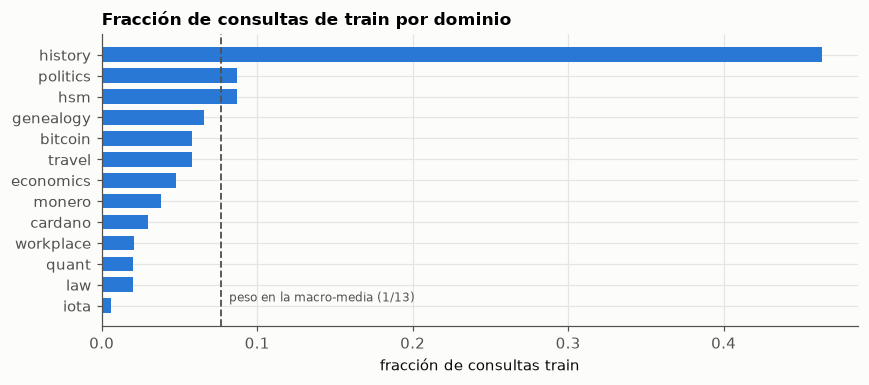

In [7]:
# Comparación con los totales globales del manifiesto / README (v1.1).
totals = MANIFEST["totals"]
check_totals = pd.DataFrame({
    "manifiesto": [totals["track1_documents"], totals["track1_queries"], totals["track1_steps"]],
    "archivos": [
        inventory.loc["TOTAL", "docs"],
        inventory.loc["TOTAL", ["consultas_train", "consultas_dev"]].sum(),
        inventory.loc["TOTAL", ["pasos_train", "pasos_dev"]].sum(),
    ],
}, index=["documentos", "consultas", "pasos"])
check_totals["coincide"] = check_totals["manifiesto"] == check_totals["archivos"]
display(check_totals)

# Peso de cada dominio: número de consultas de train vs. peso en la macro-media (1/13).
peso = (inventory.drop("TOTAL")["consultas_train"] / inventory.loc["TOTAL", "consultas_train"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(peso.index, peso.values, color=C_GOLD, height=0.7)
ax.axvline(1 / len(DOMAINS), color=INK_MUTED, ls="--", lw=1.2)
ax.text(1 / len(DOMAINS) + 0.005, 0.2, "peso en la macro-media (1/13)", color=INK_MUTED, fontsize=8)
style_ax(ax, "Fracción de consultas de train por dominio", "fracción de consultas train")
plt.tight_layout(); plt.show()

### 1.2 Esquemas: campos, tipos, nulos y vacíos

`check_schema` recorre los registros y cuenta, por campo: ausencias, tipos inesperados, nulos y valores vacíos (cadena o lista vacía). Se revisan ambos splits porque es una comprobación de formato, no de rendimiento.

In [8]:
# Esquema esperado de cada tipo de registro: campo -> tipo de Python.
SCHEMA_EXAMPLES = {"id": str, "query": str, "gold_ids": list, "gold_answers": list}
SCHEMA_STEPS = {"id": str, "query": str, "steps": list}
SCHEMA_STEP_ITEM = {"step_id": str, "step": int, "step_instruction": str, "gold_ids": list}
SCHEMA_GUIDANCE = {"id": str, "query_guidance": dict, "gold_passage_annotations": list}
SCHEMA_QUERY_GUIDANCE = {
    "expected_granularity": str, "is_temporal_query": bool, "key_time_anchors": list,
    "quality_checks": list, "query_summary": str, "query_temporal_events": list,
    "query_temporal_signals": list, "retrieval_plan": list, "retrieval_reasoning": str,
    "temporal_intent": str, "temporal_reasoning_class_primary": str,
    "temporal_reasoning_class_secondary": list,
}
SCHEMA_ANNOTATION = {
    "confidence": float, "doc_id": str, "passage_temporal_events": list,
    "passage_temporal_signals": list, "tense_guess": str, "time_mentions": list,
    "time_scope_guess": dict,
}


def check_schema(records: list[dict], schema: dict, name: str) -> list[dict]:
    """Valida una lista de registros contra un esquema simple.

    Args:
        records: registros a revisar.
        schema: diccionario ``campo -> tipo esperado``.
        name: nombre del tipo de registro (aparece en el informe).

    Returns:
        Lista de filas ``{registro, campo, problema, n}`` solo para los problemas
        encontrados; también informa de campos inesperados (no listados en el esquema).
    """
    issues = Counter()
    for rec in records:
        for field, typ in schema.items():
            if field not in rec:
                issues[(field, "ausente")] += 1
                continue
            val = rec[field]
            if val is None:
                issues[(field, "nulo")] += 1
            elif not isinstance(val, typ) or (typ is int and isinstance(val, bool)):
                issues[(field, f"tipo {type(val).__name__}")] += 1
            elif isinstance(val, (str, list, dict)) and len(val) == 0:
                issues[(field, "vacío")] += 1
        for extra in set(rec) - set(schema):
            issues[(extra, "campo inesperado")] += 1
    return [{"registro": name, "campo": f, "problema": p, "n": n} for (f, p), n in issues.items()]


schema_rows = []
for dom in DOMAINS:
    for split in SPLITS:
        ex, st, gd = load_examples(dom, split), load_steps(dom, split), load_guidance(dom, split)
        found = (
            check_schema(ex, SCHEMA_EXAMPLES, "examples")
            + check_schema(st, SCHEMA_STEPS, "steps")
            + check_schema([s for r in st for s in r["steps"]], SCHEMA_STEP_ITEM, "steps[].item")
            + check_schema(gd, SCHEMA_GUIDANCE, "guidance")
            + check_schema([g["query_guidance"] for g in gd], SCHEMA_QUERY_GUIDANCE, "query_guidance")
            + check_schema([a for g in gd for a in g["gold_passage_annotations"]], SCHEMA_ANNOTATION, "annotation")
        )
        schema_rows += [{"dominio": dom, "split": split, **r} for r in found]

schema_issues = pd.DataFrame(schema_rows, columns=["dominio", "split", "registro", "campo", "problema", "n"])
if schema_issues.empty:
    print("Sin problemas de esquema.")
else:
    display(schema_issues.groupby(["registro", "campo", "problema", "split"])["n"].sum().unstack(fill_value=0))

split                                                       dev  train
registro       campo                              problema            
annotation     passage_temporal_events            vacío     474   1194
               passage_temporal_signals           vacío     186    560
               time_mentions                      vacío     207    620
query_guidance expected_granularity               vacío      19     40
               key_time_anchors                   vacío      30     53
               quality_checks                     vacío      10     23
               query_temporal_events              vacío      87    194
               query_temporal_signals             vacío      29     61
               retrieval_plan                     vacío      10     23
               temporal_reasoning_class_primary   vacío      18     36
               temporal_reasoning_class_secondary vacío      25     49

### 1.3 Pasada única por el corpus

Para no leer 3 GB varias veces, se hace **una sola pasada** por cada `documents.jsonl` y se guarda en caché (`outputs/eda/corpus_stats/`):

- una fila de rasgos por documento (`text_features` + formato del ID + si es gold en train o en dev);
- el texto de todos los documentos gold y de una **muestra determinista del 1 %** de los no-gold (por hash del ID), que se usan después para comparar vocabulario y solapamiento léxico.

Las secciones 1.4 (integridad) y 2 (corpus) usan esta tabla.

In [9]:
STATS_DIR = CACHE_DIR / "corpus_stats"
STATS_DIR.mkdir(exist_ok=True)
SAMPLE_MOD = 100  # 1 de cada 100 documentos (por hash del ID) entra en la muestra de textos


def in_sample(doc_id: str) -> bool:
    """Decide de forma determinista si un documento entra en la muestra del 1 %."""
    return zlib.crc32(doc_id.encode()) % SAMPLE_MOD == 0


def corpus_pass(domain: str) -> pd.DataFrame:
    """Calcula (o lee de caché) los rasgos de todos los documentos de un dominio.

    Además guarda en ``<dominio>_texts.pkl`` el texto de los gold (train y dev) y de la
    muestra del 1 %, para no tener que volver a recorrer el corpus.

    Args:
        domain: nombre del dominio.

    Returns:
        DataFrame con una fila por documento: ``id``, rasgos de ``text_features``,
        ``id_format``, ``qnum``, ``num``, ``prefix80`` (primeros 80 caracteres
        normalizados, para detectar boilerplate), ``gold_train``, ``gold_dev`` y
        ``in_sample``.
    """
    stats_path = STATS_DIR / f"{domain}.parquet"
    texts_path = STATS_DIR / f"{domain}_texts.pkl"
    if stats_path.exists() and texts_path.exists():
        return pd.read_parquet(stats_path)

    gold_train, gold_dev = gold_ids_for(domain, "train"), gold_ids_for(domain, "dev")
    rows, texts = [], {}
    for doc in tqdm(iter_documents(domain), desc=domain, leave=False):
        did, content = doc["id"], doc["content"]
        sampled = in_sample(did)
        row = {"id": did, **text_features(content), **parse_doc_id(did)}
        row["prefix80"] = re.sub(r"\s+", " ", content[:80]).strip().lower()
        row["gold_train"], row["gold_dev"], row["in_sample"] = did in gold_train, did in gold_dev, sampled
        rows.append(row)
        if sampled or row["gold_train"] or row["gold_dev"]:
            texts[did] = content

    df = pd.DataFrame(rows)
    df.to_parquet(stats_path, index=False)
    with open(texts_path, "wb") as f:
        pickle.dump(texts, f)
    return df


def load_texts(domain: str) -> dict[str, str]:
    """Devuelve ``{id: texto}`` de los gold y de la muestra del 1 % (de la caché)."""
    with open(STATS_DIR / f"{domain}_texts.pkl", "rb") as f:
        return pickle.load(f)


t0 = time.time()
stats = pd.concat([corpus_pass(d).assign(domain=d) for d in tqdm(DOMAINS, desc="corpus")], ignore_index=True)
print(f"{len(stats):,} documentos procesados en {time.time() - t0:.0f} s")
stats.head(3)

corpus:   0%|          | 0/13 [00:00<?, ?it/s]

1,167,159 documentos procesados en 0 s


,id,n_chars,n_words,n_years,n_dates,n_months,n_decades,n_relative,has_html,has_markdown,non_ascii_frac,id_format,qnum,num,prefix80,gold_train,gold_dev,in_sample,domain
0,bitcoin/124973_2f09943074923e4c_93.txt,1259,223,0,0,0,0,0,False,False,0.007149,largo,124973,93,figure 3-15. matcha adds an extra step to its trade modal when the expected sli,False,False,False,bitcoin
1,bitcoin/124303_147988f584d93604_491.txt,1459,236,2,0,0,0,2,False,False,0.028101,largo,124303,491,"notably, however, altman made these statements about staying private while on a",False,False,False,bitcoin
2,bitcoin/119677_229b3a2051154226_758.txt,4054,635,2,0,1,0,5,False,False,0.000247,largo,119677,758,serious vulnerabilities not disd to the manufacturers places huge swathes of the,False,False,False,bitcoin


### 1.4 Integridad de IDs

Comprobaciones, por dominio y split:

1. todo `gold_id` de `examples` y `steps` existe en `documents.jsonl`;
2. los pares (consulta, doc) de los qrels coinciden con los `gold_ids` (1a con `examples`, 1b con `steps`);
3. cada `step_id` tiene la forma `<query_id>_step<n>` y `n` coincide con el campo `step`;
4. ningún ID eliminado por la deduplicación (`duplicate_map.json`) aparece en qrels, `gold_ids` o guidance, ni en el corpus; y todo ID conservado existe;
5. no hay `gold_ids` repetidos dentro de una misma consulta o paso.

Todas las anomalías se acumulan en una lista `anomalias` que se resume al final de la sección 1.

In [10]:
anomalias: list[dict] = []  # registro global de anomalías (dominio, split, chequeo, n, ejemplo)


def report(domain: str, split: str, check: str, bad: list) -> None:
    """Añade una anomalía al registro global si la lista ``bad`` no está vacía.

    Args:
        domain: dominio afectado.
        split: split afectado (o ``"-"`` si no aplica).
        check: descripción corta del chequeo que falló.
        bad: elementos que fallaron; se guarda el número y un ejemplo.
    """
    if bad:
        anomalias.append({"dominio": domain, "split": split, "chequeo": check, "n": len(bad), "ejemplo": str(bad[0])[:120]})


def pairs_from_records(records: list[dict], subtrack: str) -> set[tuple[str, str]]:
    """Extrae los pares (qid, doc) de los ``gold_ids`` de examples (1a) o steps (1b)."""
    if subtrack == "1a":
        return {(r["id"], g) for r in records for g in r["gold_ids"]}
    return {(s["step_id"], g) for r in records for s in r["steps"] for g in s["gold_ids"]}


def pairs_from_qrels(qrels: dict) -> set[tuple[str, str]]:
    """Convierte ``{qid: {doc: rel}}`` en el conjunto de pares (qid, doc) con rel > 0."""
    return {(q, d) for q, docs in qrels.items() for d, rel in docs.items() if rel > 0}


integrity_rows = []
for dom in DOMAINS:
    doc_ids = set(stats.loc[stats["domain"] == dom, "id"])
    dup_map = load_duplicate_map(dom)
    report(dom, "-", "ID eliminado (dup_map) presente en el corpus", sorted(set(dup_map) & doc_ids))
    report(dom, "-", "ID conservado (dup_map) ausente del corpus", sorted(set(dup_map.values()) - doc_ids))

    for split in SPLITS:
        ex, st, gd = load_examples(dom, split), load_steps(dom, split), load_guidance(dom, split)
        q1a, q1b = load_qrels(dom, split, "1a"), load_qrels(dom, split, "1b")

        gold_ex = {g for r in ex for g in r["gold_ids"]}
        gold_st = {g for r in st for s in r["steps"] for g in s["gold_ids"]}
        gold_qrels = {d for q in (q1a, q1b) for docs in q.values() for d in docs}
        gold_gd = {a["doc_id"] for g in gd for a in g["gold_passage_annotations"]}

        # 1. Existencia en el corpus
        report(dom, split, "gold_id de examples ausente del corpus", sorted(gold_ex - doc_ids))
        report(dom, split, "gold_id de steps ausente del corpus", sorted(gold_st - doc_ids))
        report(dom, split, "doc de qrels ausente del corpus", sorted(gold_qrels - doc_ids))
        report(dom, split, "doc_id de guidance ausente del corpus", sorted(gold_gd - doc_ids))

        # 2. Coherencia qrels <-> gold_ids
        for sub, recs, qr in (("1a", ex, q1a), ("1b", st, q1b)):
            a, b = pairs_from_records(recs, sub), pairs_from_qrels(qr)
            report(dom, split, f"{sub}: par en gold_ids pero no en qrels", sorted(a - b))
            report(dom, split, f"{sub}: par en qrels pero no en gold_ids", sorted(b - a))

        # 3. Formato de step_id
        bad_ids = [s["step_id"] for r in st for s in r["steps"] if s["step_id"] != f"{r['id']}_step{s['step']}"]
        report(dom, split, "step_id no sigue <query_id>_step<n>", bad_ids)

        # 4. IDs deduplicados no deben aparecer en ningún archivo de tareas
        report(dom, split, "ID eliminado (dup_map) usado en qrels/gold/guidance",
               sorted(set(dup_map) & (gold_ex | gold_st | gold_qrels | gold_gd)))

        # 5. Gold repetidos dentro de una consulta/paso
        rep = [r["id"] for r in ex if len(r["gold_ids"]) != len(set(r["gold_ids"]))]
        rep += [s["step_id"] for r in st for s in r["steps"] if len(s["gold_ids"]) != len(set(s["gold_ids"]))]
        report(dom, split, "gold_ids repetidos en una consulta/paso", rep)

        integrity_rows.append({"dominio": dom, "split": split, "gold_1a": len(gold_ex), "gold_1b": len(gold_st),
                               "gold_guidance": len(gold_gd), "dup_map": len(dup_map)})

display(pd.DataFrame(integrity_rows).pivot(index="dominio", columns="split"))
print(f"Anomalías de integridad registradas: {len(anomalias)}")

gold_1a       gold_1b       gold_guidance       dup_map        
split         dev train     dev train           dev train     dev   train
dominio                                                                  
bitcoin        92   222      59   158            92   222   76585   76585
cardano        42    80      32    52            42    80   39692   39692
economics      94   202      75   147            94   202   19064   19064
genealogy      94   231      64   159            94   231   20127   20127
history      1010  2531     667  1561          1010  2531  156241  156241
hsm           115   252      89   208           115   252   44266   44266
iota            9    28       6    18             9    28     692     692
law            29    76      24    59            29    76    7178    7178
monero         47   110      27    69            47   110   31138   31138
politics      123   283     105   228           123   283   48187   48187
quant          21    59      14    43            21    59    3745    3745
travel         72   182      55   129            72   182   18906   18906
workplace      29    73      22    36            29    73   21075   21075

Anomalías de integridad registradas: 0


### 1.5 Split manifest: IDs y solapamiento train/dev

In [11]:
split_rows = []
for dom in DOMAINS:
    man = MANIFEST["track1_tempo"][dom]
    ids_file = {s: {r["id"] for r in load_examples(dom, s)} for s in SPLITS}
    ids_steps = {s: {r["id"] for r in load_steps(dom, s)} for s in SPLITS}
    ids_guid = {s: {r["id"] for r in load_guidance(dom, s)} for s in SPLITS}
    ids_man = {s: set(man[f"{s}_ids"]) for s in SPLITS}
    for s in SPLITS:
        report(dom, s, "examples ≠ manifiesto", sorted(ids_file[s] ^ ids_man[s]))
        report(dom, s, "guidance ≠ examples", sorted(ids_guid[s] ^ ids_file[s]))
        report(dom, s, "steps contiene consultas que no están en examples", sorted(ids_steps[s] - ids_file[s]))
    # Una consulta no puede estar en ambos splits (ni sus pasos ni su guidance)
    overlap = (ids_file["train"] | ids_steps["train"] | ids_guid["train"]) & (ids_file["dev"] | ids_steps["dev"] | ids_guid["dev"])
    report(dom, "train∩dev", "consulta en train y dev", sorted(overlap))
    split_rows.append({"dominio": dom, "train_manifest": len(ids_man["train"]), "dev_manifest": len(ids_man["dev"]),
                       "coincide_train": ids_file["train"] == ids_man["train"],
                       "coincide_dev": ids_file["dev"] == ids_man["dev"], "solape_train_dev": len(overlap)})

display(pd.DataFrame(split_rows).set_index("dominio"))

,train_manifest,dev_manifest,coincide_train,coincide_dev,solape_train_dev
dominio,,,,,
bitcoin,70,30,True,True,0
cardano,36,15,True,True,0
economics,58,25,True,True,0
genealogy,80,35,True,True,0
history,561,240,True,True,0
hsm,105,45,True,True,0
iota,7,3,True,True,0
law,24,11,True,True,0
monero,46,19,True,True,0


### 1.6 Relación 1a ↔ 1b

¿Todas las consultas de `examples` tienen registro en `steps`? ¿Cuántos pasos se conservan respecto a la numeración (`step` 1..n)? Un paso "hueco" es un número de paso que falta entre 1 y el máximo presente.

In [12]:
def relation_1a_1b(domain: str, split: str = SPLIT) -> dict:
    """Resume la cobertura de los pasos (1b) respecto a las consultas (1a).

    Args:
        domain: nombre del dominio.
        split: split a analizar.

    Returns:
        Diccionario con: consultas totales, consultas con registro de pasos, pasos
        presentes, pasos sin gold, pasos "hueco" (números ausentes entre 1 y el máximo)
        y si el texto de la consulta coincide entre ``examples`` y ``steps``.
    """
    ex = {r["id"]: r for r in load_examples(domain, split)}
    st = load_steps(domain, split)
    gaps, no_gold, same_query = 0, 0, 0
    for r in st:
        nums = sorted(s["step"] for s in r["steps"])
        gaps += max(nums) - len(nums) if nums else 0
        no_gold += sum(1 for s in r["steps"] if not s["gold_ids"])
        same_query += ex[r["id"]]["query"] == r["query"]
    return {
        "consultas": len(ex), "con_pasos": len(st), "sin_pasos": len(ex) - len(st),
        "pasos": sum(len(r["steps"]) for r in st), "pasos_sin_gold": no_gold,
        "pasos_hueco": gaps, "query_identica": same_query == len(st),
    }


rel = add_total_row(pd.DataFrame([{"dominio": d, **relation_1a_1b(d)} for d in DOMAINS]).set_index("dominio"),
                    all_cols=("query_identica",))
rel["%_con_pasos"] = (100 * rel["con_pasos"] / rel["consultas"]).astype(float).round(1)
display(rel)

,consultas,con_pasos,sin_pasos,pasos,pasos_sin_gold,pasos_hueco,query_identica,%_con_pasos
dominio,,,,,,,,
bitcoin,70,61,9,132,0,23,True,87.1
cardano,36,28,8,57,0,13,True,77.8
economics,58,54,4,130,0,32,True,93.1
genealogy,80,71,9,159,0,53,True,88.8
history,561,538,23,1421,0,260,True,95.9
hsm,105,102,3,254,0,41,True,97.1
iota,7,7,0,16,0,4,True,100.0
law,24,23,1,53,0,14,True,95.8
monero,46,34,12,73,0,14,True,73.9


### 1.7 Resumen de anomalías (sección 1)

In [13]:
anom_df = pd.DataFrame(anomalias, columns=["dominio", "split", "chequeo", "n", "ejemplo"])
if anom_df.empty:
    print("No se encontraron anomalías estructurales.")
else:
    display(anom_df.groupby(["chequeo", "split"])["n"].agg(["sum", "count"]).rename(columns={"sum": "casos", "count": "dominios"}))
    display(anom_df.head(20))

No se encontraron anomalías estructurales.


## 2. Corpus (`documents.jsonl`)

### 2.1 Longitud de los documentos

Se mide en caracteres, en palabras (`\w+`) y en **tokens del tokenizador de BGE** (WordPiece, el mismo que usa el baseline denso de `baseline_track1_tempo.ipynb`) sobre una muestra. Los tokens determinan si hace falta *chunking*: los encoders tipo BERT truncan a 512 tokens.

In [14]:
def percentile_table(df: pd.DataFrame, col: str, by: str = "domain",
                     qs=(0.01, 0.25, 0.5, 0.75, 0.9, 0.99)) -> pd.DataFrame:
    """Tabla de percentiles de una columna numérica agrupada por otra columna.

    Args:
        df: DataFrame de entrada.
        col: columna numérica a describir.
        by: columna de agrupación.
        qs: percentiles a calcular (fracciones entre 0 y 1).

    Returns:
        DataFrame con una fila por grupo, columnas ``p1 … p99``, media y máximo.
    """
    t = df.groupby(by)[col].quantile(list(qs)).unstack()
    t.columns = [f"p{int(q * 100)}" for q in qs]
    t["media"] = df.groupby(by)[col].mean()
    t["max"] = df.groupby(by)[col].max()
    return t.round(0).astype(int).sort_values("p50")


display(Markdown("**Palabras por documento**"))
display(percentile_table(stats, "n_words"))

**Palabras por documento**

,p1,p25,p50,p75,p90,p99,media,max
domain,,,,,,,,
history,14,57,108,241,796,9180,570,40536
law,18,114,149,227,430,2778,353,272501
workplace,15,113,149,225,407,1830,285,251834
bitcoin,18,115,153,223,320,1605,304,1475910
monero,16,115,153,223,374,2191,334,914548
economics,22,115,154,239,426,2259,334,272501
politics,24,121,154,240,443,2707,350,491193
quant,22,118,157,219,353,2268,308,257596
cardano,16,122,158,218,279,1431,279,745401


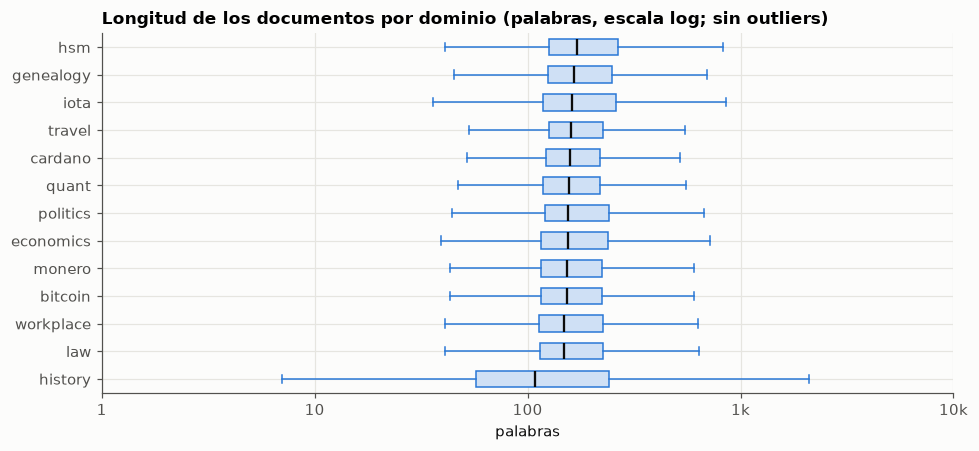

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
order = stats.groupby("domain")["n_words"].median().sort_values().index
data = [np.log10(stats.loc[stats["domain"] == d, "n_words"].clip(lower=1)) for d in order]
bp = ax.boxplot(data, orientation="horizontal", tick_labels=order, showfliers=False, widths=0.6, patch_artist=True,
                medianprops={"color": INK, "lw": 1.5}, boxprops={"facecolor": "#cfe0f5", "edgecolor": C_GOLD},
                whiskerprops={"color": C_GOLD}, capprops={"color": C_GOLD})
ax.set_xticks([0, 1, 2, 3, 4], ["1", "10", "100", "1k", "10k"])
style_ax(ax, "Longitud de los documentos por dominio (palabras, escala log; sin outliers)", "palabras")
plt.tight_layout(); plt.show()

In [16]:
# Tokens de subpalabra: se tokeniza una muestra (la muestra determinista del 1 %, máx. 1000 por dominio)
# con el tokenizador de BGE y se estima la razón tokens/palabra y el % de documentos que superan 512 tokens.
from transformers import AutoTokenizer

DENSE_MODEL = "BAAI/bge-small-en-v1.5"
tokenizer = AutoTokenizer.from_pretrained(DENSE_MODEL)

tok_rows = []
for dom in DOMAINS:
    texts = load_texts(dom)
    sample_ids = stats.loc[(stats["domain"] == dom) & stats["in_sample"], "id"].tolist()[:1000]
    n_tok = [len(tokenizer(texts[i], add_special_tokens=False)["input_ids"]) for i in sample_ids]
    n_wrd = stats.set_index("id").loc[sample_ids, "n_words"].to_numpy()
    n_tok = np.array(n_tok)
    tok_rows.append({
        "dominio": dom, "muestra": len(sample_ids),
        "tokens_p50": int(np.median(n_tok)), "tokens_p90": int(np.percentile(n_tok, 90)),
        "tokens/palabra": round(n_tok.sum() / max(n_wrd.sum(), 1), 2),
        "%>256": round(100 * (n_tok > 256).mean(), 1), "%>512": round(100 * (n_tok > 512).mean(), 1),
    })
tok_df = pd.DataFrame(tok_rows).set_index("dominio").sort_values("%>512")
display(tok_df)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (541 > 512). Running this sequence through the model will result in indexing errors


,muestra,tokens_p50,tokens_p90,tokens/palabra,%>256,%>512
dominio,,,,,,
quant,265,203,466,1.40,36.2,9.1
workplace,416,194,487,1.28,31.0,9.4
cardano,484,219,495,1.52,36.4,9.9
law,362,183,503,1.29,28.5,9.9
politics,1000,196,561,1.41,33.5,12.2
monero,538,204,575,1.50,32.9,12.3
economics,738,197,636,1.55,33.1,12.9
bitcoin,771,235,581,1.54,41.4,13.2
genealogy,1000,236,619,1.46,43.2,14.8


### 2.2 Documentos vacíos, boilerplate y casi-duplicados

- **Vacíos / casi vacíos:** menos de 10 palabras.
- **Boilerplate:** prefijos de 80 caracteres que se repiten en muchos documentos (licencias, avisos, cabeceras de menú). La deduplicación v1.1 solo eliminó copias *idénticas*, así que las variaciones mínimas sobreviven.
- **Casi-duplicados:** MinHash + LSH (implementado aquí con numpy) sobre shingles de 5 palabras en los dominios pequeños.

In [17]:
casi_vacio = stats["n_words"] < 10
short = stats.assign(casi_vacio=casi_vacio, gold_casi_vacio=casi_vacio & stats["gold_train"]).groupby("domain").agg(
    docs=("id", "size"), casi_vacios=("casi_vacio", "sum"), gold_casi_vacios=("gold_casi_vacio", "sum"))
short["%"] = (100 * short["casi_vacios"] / short["docs"]).round(2)
display(short.sort_values("%", ascending=False))

print("Ejemplos de documentos casi vacíos:")
display(stats.loc[stats["n_words"] < 10, ["domain", "id", "n_words", "prefix80"]].sample(8, random_state=SEED))

,docs,casi_vacios,gold_casi_vacios,%
domain,,,,
history,200252,637,2,0.32
monero,53955,150,0,0.28
cardano,47509,125,0,0.26
bitcoin,76706,192,0,0.25
workplace,43584,109,0,0.25
quant,25040,44,0,0.18
economics,74692,86,0,0.12
iota,9680,12,0,0.12
law,36110,38,0,0.11


Ejemplos de documentos casi vacíos:


,domain,id,n_words,prefix80
864668,politics,politics/e52857e3_5509.txt,9,austrian public schools do not generally employ dress codes.
437041,history,history/fa10d82d_35749.txt,9,our history & vision museum facilities learn about simon wiesenthal
756839,monero,monero/dc3026a9_12538.txt,7,"specific:: * bitcoin-based, * cryptonote-based, * nxt-based,"
491602,history,history/3bc27fdd_37886.txt,9,a2.5 sperm donation for stem cell research download
738252,law,law/50689ced_2916.txt,8,reluctantly retired oldies solve crimes. funny and sweet.
1154461,workplace,workplace/55a0f162_11222.txt,9,43 [repealed 2002-42-22.] part 5 — statutory holidays
434395,history,history/76e62e24_33067.txt,8,more ancient prophecies jerome friedman pages 225-238
502406,history,history/dfbd2404_2660.txt,8,why do ebooks get removed? upcoming ebook removals


In [18]:
def boilerplate_prefixes(df: pd.DataFrame, min_count: int = 50, top: int = 15) -> pd.DataFrame:
    """Encuentra los prefijos de 80 caracteres más repetidos (posible boilerplate).

    Args:
        df: tabla de rasgos del corpus (debe tener ``prefix80``, ``domain`` y ``gold_train``).
        min_count: número mínimo de documentos con el mismo prefijo.
        top: cuántos prefijos devolver.

    Returns:
        DataFrame con el prefijo, el número de documentos, cuántos dominios lo
        comparten y cuántos de esos documentos son gold en train.
    """
    g = df[df["prefix80"].str.len() >= 30].groupby("prefix80").agg(
        docs=("id", "size"), dominios=("domain", "nunique"), gold_train=("gold_train", "sum"))
    return g[g["docs"] >= min_count].sort_values("docs", ascending=False).head(top)


bp_df = boilerplate_prefixes(stats)
display(bp_df)
n_bp = stats["prefix80"].map(stats["prefix80"].value_counts()).ge(50).sum()
print(f"Documentos cuyo prefijo se repite ≥50 veces: {n_bp:,} ({100 * n_bp / len(stats):.1f} % del corpus)")

,docs,dominios,gold_train
prefix80,,,
* [click to on facebook (opens in new window) facebook](https://berndpulch.org/,291,1,0
authority control databases edit this at wikidata !-- image -- ----------,201,7,0
click to share on x (opens in new window) x click to share on facebook (opens in,118,10,0
"required, but never shown by clicking “post your answer”, you agree to our terms",114,8,0
party party candidate votes ----------------- ---------------------,111,1,0
"legal/policy framework the constitution provides for freedom of religion, and th",99,1,0
is there a source from the ancient world that you find yourself coming back to w,97,1,0
"semester course; 3 lecture hours (delivered online, face-to-face or hybrid). 3 c",97,1,0
start asking to get answers find the answer to your question by asking. explore,89,10,0


Documentos cuyo prefijo se repite ≥50 veces: 2,115 (0.2 % del corpus)


In [19]:
SHINGLE = 5          # palabras por shingle
NUM_PERM = 64        # número de permutaciones (funciones hash) de MinHash
BANDS = 16           # LSH: 16 bandas x 4 filas -> umbral efectivo de Jaccard ≈ (1/16)^(1/4) ≈ 0.5
MERSENNE = np.uint64((1 << 61) - 1)

_rng = np.random.default_rng(SEED)
_A = _rng.integers(1, 1 << 31, NUM_PERM, dtype=np.uint64)
_B = _rng.integers(0, 1 << 31, NUM_PERM, dtype=np.uint64)


def minhash_signature(text: str) -> np.ndarray:
    """Calcula la firma MinHash de un texto.

    El texto se pasa a minúsculas, se parte en palabras y se convierte en shingles
    (n-gramas) de ``SHINGLE`` palabras, cada uno con hash crc32. La firma es, para
    cada una de las ``NUM_PERM`` funciones ``(a·x + b) mod p``, el mínimo sobre los shingles.

    Args:
        text: contenido del documento.

    Returns:
        Vector ``uint64`` de longitud ``NUM_PERM``. La fracción de posiciones iguales
        entre dos firmas estima su similitud de Jaccard.
    """
    words = WORD_RE.findall(text.lower())
    if len(words) < SHINGLE:
        words = words + [""] * (SHINGLE - len(words))
    shingles = {" ".join(words[i:i + SHINGLE]) for i in range(len(words) - SHINGLE + 1)}
    x = np.fromiter((zlib.crc32(s.encode()) for s in shingles), dtype=np.uint64, count=len(shingles))
    return ((_A[:, None] * x[None, :] + _B[:, None]) % MERSENNE).min(axis=1)


def near_duplicate_pairs(ids: list[str], sigs: np.ndarray, threshold: float = 0.8,
                         max_bucket: int = 200) -> pd.DataFrame:
    """Busca pares de casi-duplicados con LSH sobre firmas MinHash.

    Cada firma se parte en ``BANDS`` bandas; dos documentos son candidatos si coinciden
    en alguna banda completa. Los candidatos se filtran por Jaccard estimado.

    Args:
        ids: IDs de los documentos, en el mismo orden que ``sigs``.
        sigs: matriz ``(n_docs, NUM_PERM)`` de firmas.
        threshold: Jaccard estimado mínimo para considerar un par casi-duplicado.
        max_bucket: los buckets más grandes que esto (boilerplate masivo) se ignoran
            para no generar millones de pares; se informa cuántos hubo.

    Returns:
        DataFrame ``{doc_a, doc_b, jaccard}`` con los pares que superan el umbral.
        El atributo ``attrs["buckets_grandes"]`` cuenta los buckets ignorados.
    """
    rows_per_band = NUM_PERM // BANDS
    candidates, big = set(), 0
    for b in range(BANDS):
        buckets = defaultdict(list)
        band = sigs[:, b * rows_per_band:(b + 1) * rows_per_band]
        for i, key in enumerate(map(bytes, band)):
            buckets[key].append(i)
        for members in buckets.values():
            if len(members) > max_bucket:
                big += 1
                continue
            candidates.update(combinations(members, 2))
    out = []
    for i, j in candidates:
        jac = float((sigs[i] == sigs[j]).mean())
        if jac >= threshold:
            out.append((ids[i], ids[j], jac))
    df = pd.DataFrame(out, columns=["doc_a", "doc_b", "jaccard"])
    df.attrs["buckets_grandes"] = big
    return df


NEARDUP_DOMAINS = ["iota", "quant", "law", "workplace"]
neardup_rows, neardup_examples = [], {}
for dom in NEARDUP_DOMAINS:
    cache = CACHE_DIR / f"minhash_{dom}.npz"
    if cache.exists():
        z = np.load(cache, allow_pickle=True)
        ids, sigs = list(z["ids"]), z["sigs"]
    else:
        ids, sig_list = [], []
        for doc in tqdm(iter_documents(dom), desc=f"minhash {dom}", leave=False):
            ids.append(doc["id"])
            sig_list.append(minhash_signature(doc["content"]))
        sigs = np.vstack(sig_list)
        np.savez(cache, ids=np.array(ids), sigs=sigs)
    pairs = near_duplicate_pairs(ids, sigs, threshold=0.8)
    gold = gold_ids_for(dom, "train")
    in_pairs = set(pairs["doc_a"]) | set(pairs["doc_b"])
    neardup_rows.append({
        "dominio": dom, "docs": len(ids), "pares_J≥0.8": len(pairs),
        "pares_J≥0.9": int((pairs["jaccard"] >= 0.9).sum()),
        "docs_implicados": len(in_pairs), "%docs": round(100 * len(in_pairs) / len(ids), 1),
        "gold_train_implicados": len(in_pairs & gold),
        "pares_gold–no_gold": int(sum((a in gold) != (b in gold) for a, b in zip(pairs["doc_a"], pairs["doc_b"]))),
        "buckets_grandes": pairs.attrs["buckets_grandes"],
    })
    neardup_examples[dom] = pairs.sort_values("jaccard").head(3)

display(pd.DataFrame(neardup_rows).set_index("dominio"))

,docs,pares_J≥0.8,pares_J≥0.9,docs_implicados,%docs,gold_train_implicados,pares_gold–no_gold,buckets_grandes
dominio,,,,,,,,
iota,9680,603,421,850,8.8,2,0,0
quant,25040,1508,1065,2229,8.9,3,3,0
law,36110,3149,2089,4118,11.4,8,34,0
workplace,43584,3310,2173,4841,11.1,6,5,0


In [20]:
# Ejemplo de un par casi-duplicado (no idéntico) en un dominio pequeño, para ver qué tipo de diferencia sobrevive.
dom = "law"
ex_pair = neardup_examples[dom]
if len(ex_pair):
    a, b, j = ex_pair.iloc[0]
    want = {a, b}
    found = {d["id"]: d["content"] for d in iter_documents(dom) if d["id"] in want}
    print(f"Jaccard estimado: {j:.2f}\n--- {a}\n{found[a][:400]}\n--- {b}\n{found[b][:400]}")

Jaccard estimado: 0.81
--- law/eb41e729_4312.txt
Posted by William Byrnes on April 15, 2022 The Texas A&M graduate program for tax, wealth, and risk management is accepting applications from financial professionals with at least five years of industry experience for the summer. Even though our graduate program has grown to over 750 enrollment, the enrollment for a course section is between 20 and the maximum of 30 so that each student receives m
--- law/ac32ce9d_4256.txt
Posted by William Byrnes on August 21, 2023 Robert Bloink and Prof. William Byrnes’ (Texas A&M Law) weekly Tax Facts Intelligence strategy newsletter for financial advisors is available via the Tax Facts app or search.TaxFactsOnline.com


### 2.3 Formato, idioma y caracteres raros

In [21]:
fmt = stats.groupby("domain").agg(
    html=("has_html", "mean"), markdown=("has_markdown", "mean"),
    non_ascii_medio=("non_ascii_frac", "mean"),
    pct_non_ascii_gt_20=("non_ascii_frac", lambda s: (s > 0.2).mean()),
)
display((100 * fmt).round(2).rename(columns=lambda c: f"% {c}"))

print("Documentos con >20 % de caracteres no ASCII (posible otro idioma o símbolos):")
odd = stats[stats["non_ascii_frac"] > 0.2]
if len(odd):
    display(odd.sample(min(8, len(odd)), random_state=SEED)[["domain", "id", "non_ascii_frac", "prefix80"]])
print("Ejemplos de documentos con HTML:")
display(stats[stats["has_html"]].sample(5, random_state=SEED)[["domain", "id", "prefix80"]])

,% html,% markdown,% non_ascii_medio,% pct_non_ascii_gt_20
domain,,,,
bitcoin,0.02,11.37,0.46,0.28
cardano,0.02,11.07,0.22,0.00
economics,0.01,7.58,0.31,0.03
genealogy,0.01,7.09,0.39,0.00
history,0.01,0.39,0.32,0.30
hsm,0.01,4.46,0.50,0.04
iota,0.05,7.52,0.40,0.00
law,0.00,7.36,0.37,0.01
monero,0.01,7.01,0.52,0.55


Documentos con >20 % de caracteres no ASCII (posible otro idioma o símbolos):


,domain,id,non_ascii_frac,prefix80
547930,hsm,hsm/5d52909f_208796.txt,0.238267,- العربية) - ব ল ) - català - чӑвашла) - dansk) - deutsch - eesti) - español -
911182,politics,politics/39880790_10617.txt,0.327988,"the idf confirms carrying out an airstrike in southern lebanon this morning, kil"
435012,history,history/fd45306f_338228.txt,0.245283,- català - čeština - dansk - deutsch - español - فارسی - français - 한국어 - italia
459183,history,history/0237c899_172412.txt,0.245682,- afrikaans - alemannisch - አማርኛ - العربية - aragonés - ܐܪܡܝܐ - অসম য - asturi
21236,bitcoin,bitcoin/121815_02c695d1fb810aea_475.txt,0.238962,立即下載九州app，體驗最極致的娛樂樂趣！九州娛樂城——您的最佳線上娛樂夥伴！ 13496. buying prescription drugs in mexi
60305,bitcoin,bitcoin/121815_02c695d1fb810aea_177.txt,0.216735,4351. 4352. онлайн казино с депозитом https://remvend-cafe.ru/igrat-onlayn/igrov
448958,history,history/2dca53eb_195676.txt,0.426117,!-- image -- 10. η ελληνοφρένεια και τα όρια της ελευθερίας της πληροφόρησης -
765690,monero,monero/4083_e2c8647e8796b519_448.txt,0.217146,"oil prices are in a rout, with no clear sign of the bottom yet. january 29th 201"


Ejemplos de documentos con HTML:


,domain,id,prefix80
925449,politics,politics/56a1b71c_29333.txt,<p>intervenors&rsquo; response to the motion for unitary status as filed by the
400842,history,history/26dab88b_37533.txt,"this section is non-normative. beyond the syntax of the language, this specifica"
16462,bitcoin,bitcoin/42827bf7_8782.txt,the xml namespace that should be used in xml binding files has changed. the http
970713,travel,travel/192052_edc012032504943a_190.txt,introduction pursuing an mba (master of business administration) program oversea
411251,history,history/a4b263b8_53731.txt,alvin plantinga says in where the conflict really lies that a clockwork determin


### 2.4 Estructura de los IDs y posible leakage

Hay dos formatos de ID:

- **corto:** `<dominio>/<hash8>_<n>.txt`
- **largo:** `<dominio>/<número>_<hash16>_<n>.txt`

Se comprueba qué formato tienen los gold, si el `<número>` de los IDs largos coincide con el número de pregunta de StackExchange de alguna consulta (la parte antes de `_` en el `id` de la consulta) y si los sufijos `<n>` de los gold de una consulta son consecutivos. Cualquier patrón de este tipo **no debe explotarse**: es un artefacto de construcción del dataset y no tiene por qué mantenerse en test.

In [22]:
fmt_gold = pd.crosstab(stats["id_format"], stats["gold_train"] | stats["gold_dev"], margins=True)
fmt_gold.columns = ["no_gold", "gold", "total"] if fmt_gold.shape[1] == 3 else fmt_gold.columns
display(Markdown("**Formato de ID vs. gold (train ∪ dev), todos los dominios**"))
display(fmt_gold)

display(Markdown("**% de IDs largos por dominio**"))
display((100 * pd.crosstab(stats["domain"], stats["id_format"], normalize="index")).round(1))

**Formato de ID vs. gold (train ∪ dev), todos los dominios**

,no_gold,gold,total
id_format,,,
corto,379933,6098,386031
largo,781128,0,781128
All,1161061,6098,1167159


**% de IDs largos por dominio**

id_format,corto,largo
domain,,
bitcoin,25.7,74.3
cardano,20.8,79.2
economics,29.6,70.4
genealogy,11.2,88.8
history,100.0,0.0
hsm,13.5,86.5
iota,22.0,78.0
law,27.3,72.7
monero,23.3,76.7


In [23]:
def query_number(qid: str) -> str:
    """Devuelve el número de pregunta de StackExchange de un id de consulta (``"112346_808"`` → ``"112346"``)."""
    return qid.split("_")[0]


leak_rows = []
for dom in DOMAINS:
    q_train = {query_number(r["id"]) for r in load_examples(dom, "train")}
    q_dev = {query_number(r["id"]) for r in load_examples(dom, "dev")}
    long_docs = stats[(stats["domain"] == dom) & (stats["id_format"] == "largo")]
    qn = long_docs["qnum"]
    leak_rows.append({
        "dominio": dom, "docs_largos": len(long_docs),
        "%prefijo=consulta_train": round(100 * qn.isin(q_train).mean(), 1) if len(qn) else np.nan,
        "%prefijo=consulta_dev": round(100 * qn.isin(q_dev).mean(), 1) if len(qn) else np.nan,
        "prefijos_distintos": qn.nunique(),
        "consultas_train_con_docs_largos": len(q_train & set(qn)), "consultas_train": len(q_train),
    })
display(pd.DataFrame(leak_rows).set_index("dominio"))

,docs_largos,%prefijo=consulta_train,%prefijo=consulta_dev,prefijos_distintos,consultas_train_con_docs_largos,consultas_train
dominio,,,,,,
bitcoin,57002,49.6,50.4,88,61,70
cardano,37620,74.8,25.2,37,26,36
economics,52553,75.8,24.2,82,57,58
genealogy,120908,70.8,29.2,100,71,80
history,0,NaN,NaN,0,0,561
hsm,146685,75.9,24.1,143,101,105
iota,7549,93.8,6.2,8,6,7
law,26237,66.3,33.7,35,24,24
monero,41372,69.5,30.5,57,42,46


In [24]:
def consecutive_gold_fraction(domain: str, split: str = SPLIT) -> float:
    """Fracción de consultas cuyos gold (formato corto) tienen sufijos ``<n>`` consecutivos.

    Args:
        domain: nombre del dominio.
        split: split a analizar.

    Returns:
        Fracción (0–1) de consultas con ≥2 gold cuyos números forman un rango sin huecos.
    """
    ok, total = 0, 0
    for r in load_examples(domain, split):
        nums = sorted(n for n in (parse_doc_id(g)["num"] for g in r["gold_ids"]) if n is not None)
        if len(nums) >= 2:
            total += 1
            ok += nums[-1] - nums[0] + 1 == len(nums)
    return ok / total if total else np.nan


consec = pd.Series({d: consecutive_gold_fraction(d) for d in DOMAINS}, name="% consultas con gold consecutivos")
display((100 * consec).round(1).to_frame())

,% consultas con gold consecutivos
bitcoin,86.2
cardano,100.0
economics,98.0
genealogy,96.9
history,98.1
hsm,100.0
iota,85.7
law,100.0
monero,74.4
politics,100.0


### 2.5 Densidad temporal: gold vs. no-gold

Expresiones temporales por cada 100 palabras (años + fechas + meses con número + décadas/siglos) y proporción de documentos con al menos un año. Se compara **gold de train** contra **no-gold** (todo el resto del corpus).

In [25]:
stats["n_temporal"] = stats[["n_years", "n_dates", "n_months", "n_decades"]].sum(axis=1)
stats["temp_density"] = 100 * stats["n_temporal"] / stats["n_words"].clip(lower=1)
stats["rel_density"] = 100 * stats["n_relative"] / stats["n_words"].clip(lower=1)
stats["grupo"] = np.where(stats["gold_train"], "gold", np.where(stats["gold_dev"], "gold_dev", "no_gold"))

cmp = stats[stats["grupo"] != "gold_dev"].groupby(["domain", "grupo"]).agg(
    palabras_p50=("n_words", "median"),
    pct_con_año=("n_years", lambda s: 100 * (s > 0).mean()),
    densidad_temporal=("temp_density", "mean"),
    densidad_relativa=("rel_density", "mean"),
).round(2).unstack("grupo")
display(cmp)

palabras_p50         pct_con_año         densidad_temporal         densidad_relativa        
grupo             gold no_gold        gold no_gold              gold no_gold              gold no_gold
domain                                                                                                
bitcoin           95.0   154.0       21.62   26.07              0.50    0.52              0.63    0.42
cardano          266.5   157.0       22.50   28.21              0.40    0.51              0.63    0.43
economics        281.0   154.0       59.90   44.46              1.02    1.12              0.73    0.44
genealogy        342.0   165.0       84.42   60.56              2.55    2.48              0.62    0.60
history          217.0   106.0       54.44   47.55              1.22    1.71              0.79    0.64
hsm              747.0   170.0       85.32   39.58              1.12    0.97              0.61    0.43
iota             276.5   161.0       28.57   23.06              0.54    0.40              0.72    0.46
law              105.5   149.0       48.68   36.77              1.33    0.85              1.09    0.47
monero            67.0   153.0       16.36   22.87              0.48    0.54              0.80    0.40
politics         723.0   154.0       85.16   52.08              1.41    1.42              0.81    0.61
quant             69.0   157.0       11.86   20.65              0.51    0.40              0.40    0.39
travel            69.5   160.0       18.68   37.68              0.65    0.63              0.84    0.54
workplace        329.0   149.0       24.66   28.66              0.18    0.63              0.67    0.50

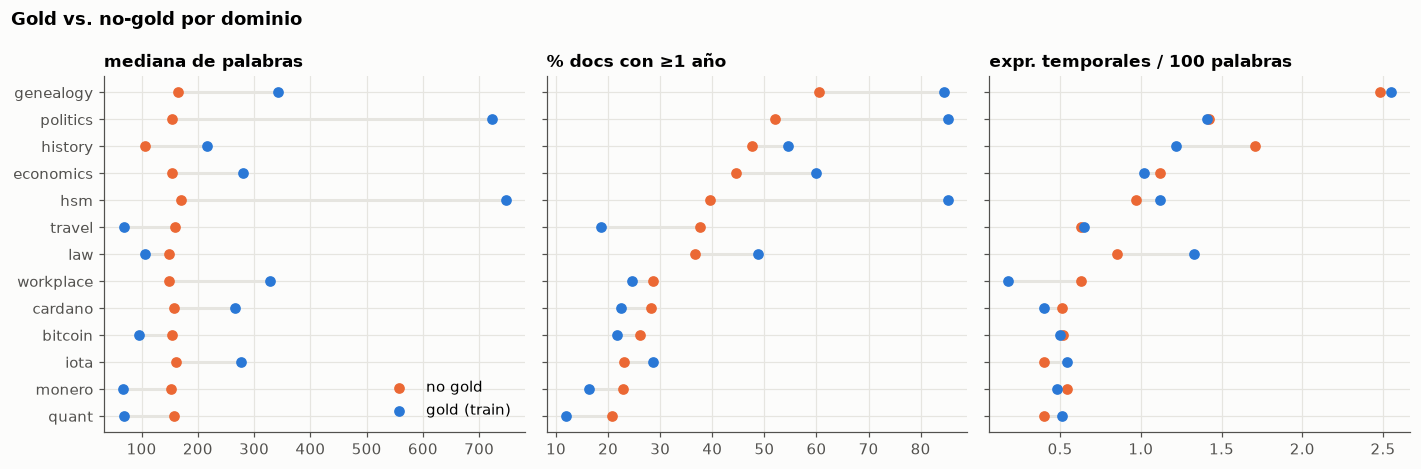

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharey=True)
order = cmp[("pct_con_año", "no_gold")].sort_values().index
y = np.arange(len(order))
for ax, (metric, label) in zip(axes, [("palabras_p50", "mediana de palabras"),
                                      ("pct_con_año", "% docs con ≥1 año"),
                                      ("densidad_temporal", "expr. temporales / 100 palabras")]):
    ax.scatter(cmp.loc[order, (metric, "no_gold")], y, color=C_NOGOLD, s=36, label="no gold", zorder=3)
    ax.scatter(cmp.loc[order, (metric, "gold")], y, color=C_GOLD, s=36, label="gold (train)", zorder=3)
    for i, d in enumerate(order):
        ax.plot([cmp.loc[d, (metric, "no_gold")], cmp.loc[d, (metric, "gold")]], [i, i], color=GRID, lw=2, zorder=2)
    ax.set_yticks(y, order)
    style_ax(ax, label)
axes[0].legend(loc="lower right")
fig.suptitle("Gold vs. no-gold por dominio", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 2.6 ¿Los gold son distinguibles por rasgos superficiales?

Se entrena una regresión logística (validación cruzada estratificada, 5 folds) para separar gold de train vs. la muestra del 1 % de no-gold, usando solo rasgos superficiales. Se reporta el AUC con y sin el **formato del ID** para medir cuánto aporta ese posible artefacto. Un AUC cercano a 0.5 significa que los rasgos no distinguen nada; cerca de 1, que basta con ellos.

Además, se comparan los **términos sobrerrepresentados** en gold vs. no-gold con *log-odds* con prior de Dirichlet (Monroe et al., 2008).

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

surf = stats[stats["gold_train"] | (stats["in_sample"] & ~stats["gold_dev"])].copy()
surf["log_words"] = np.log1p(surf["n_words"])
surf["has_year"] = surf["n_years"] > 0
surf["id_largo"] = surf["id_format"] == "largo"
base_feats = ["log_words", "temp_density", "rel_density", "has_year", "has_html", "has_markdown", "non_ascii_frac"]


def surface_auc(df: pd.DataFrame, feats: list[str]) -> float:
    """AUC medio (CV de 5 folds) de una regresión logística que predice ``gold_train``.

    Args:
        df: filas gold + muestra no-gold, con las columnas de ``feats``.
        feats: nombres de las columnas usadas como rasgos.

    Returns:
        AUC ROC medio de la validación cruzada.
    """
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    return cross_val_score(model, df[feats].astype(float), df["gold_train"], cv=cv, scoring="roc_auc").mean()


auc = pd.Series({
    "rasgos superficiales": surface_auc(surf, base_feats),
    "solo longitud": surface_auc(surf, ["log_words"]),
    "solo densidad temporal": surface_auc(surf, ["temp_density", "has_year"]),
    "superficiales + formato de ID": surface_auc(surf, base_feats + ["id_largo"]),
}, name="AUC").round(3)
print(f"gold train: {surf['gold_train'].sum():,} | no-gold (muestra): {(~surf['gold_train']).sum():,}")
display(auc.to_frame())

gold train: 4,329 | no-gold (muestra): 11,486


,AUC
rasgos superficiales,0.640
solo longitud,0.603
solo densidad temporal,0.569
superficiales + formato de ID,0.898


In [28]:
from sklearn.feature_extraction.text import CountVectorizer


def log_odds_terms(texts_a: list[str], texts_b: list[str], top: int = 20, min_df: int = 5) -> pd.DataFrame:
    """Términos más característicos de A frente a B (log-odds con prior de Dirichlet informativo).

    Args:
        texts_a: textos del grupo A (gold).
        texts_b: textos del grupo B (no-gold).
        top: cuántos términos devolver para cada lado.
        min_df: frecuencia documental mínima para considerar un término.

    Returns:
        DataFrame con los ``top`` términos de cada grupo y su z-score.
    """
    vec = CountVectorizer(stop_words="english", min_df=min_df, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
    X = vec.fit_transform(texts_a + texts_b)
    ya = np.asarray(X[: len(texts_a)].sum(0)).ravel() + 0.0
    yb = np.asarray(X[len(texts_a):].sum(0)).ravel() + 0.0
    prior = (ya + yb) / (ya + yb).sum() * 1000  # prior proporcional a la frecuencia global
    na, nb, a0 = ya.sum(), yb.sum(), prior.sum()
    delta = (np.log((ya + prior) / (na + a0 - ya - prior)) - np.log((yb + prior) / (nb + a0 - yb - prior)))
    z = delta / np.sqrt(1 / (ya + prior) + 1 / (yb + prior))
    terms = np.array(vec.get_feature_names_out())
    idx = np.argsort(z)
    return pd.DataFrame({"gold": terms[idx[::-1][:top]], "z_gold": z[idx[::-1][:top]].round(1),
                         "no_gold": terms[idx[:top]], "z_no_gold": z[idx[:top]].round(1)})


gold_texts, nongold_texts = [], []
for dom in DOMAINS:
    t = load_texts(dom)
    g = set(stats.loc[(stats["domain"] == dom) & stats["gold_train"], "id"])
    s = stats.loc[(stats["domain"] == dom) & stats["in_sample"] & ~stats["gold_train"] & ~stats["gold_dev"], "id"]
    gold_texts += [t[i] for i in g]
    nongold_texts += [t[i] for i in s]
display(log_odds_terms(gold_texts, nongold_texts))

,gold,z_gold,no_gold,z_no_gold
0,displaystyle,38.4,url,-35.6
1,span,33.9,library,-33.3
2,left,31.2,papers,-28.5
3,frac,29.6,www,-28.4
4,numbers,29.4,user,-28.0
5,mi,28.6,https,-27.2
6,camp,27.9,working,-27.0
7,election,27.6,research,-25.6
8,theorem,26.7,com,-25.1
9,lt,26.4,organization,-24.5


## 3. Consultas 1a (`examples_train.jsonl`)

### 3.1 Limpieza del HTML y longitud

Las consultas son posts de StackExchange: título (primera línea) + cuerpo HTML. Se separan con `split_query` y se mide cuánto texto es marcado HTML.

In [29]:
q_rows = []
for dom in DOMAINS:
    for r in load_examples(dom):
        title, body = split_query(r["query"])
        clean = clean_query(r["query"])
        q_rows.append({
            "domain": dom, "id": r["id"], "raw": r["query"], "title": title, "clean": clean,
            "chars_raw": len(r["query"]), "chars_clean": len(clean),
            "words_title": len(WORD_RE.findall(title)), "words_body": len(WORD_RE.findall(body)),
            "words_clean": len(WORD_RE.findall(clean)),
            "has_code": "<code>" in r["query"] or "<pre>" in r["query"],
            "has_link": "<a " in r["query"],
            "n_gold": len(r["gold_ids"]), "n_answers": len(r["gold_answers"]),
            "words_answers": sum(len(WORD_RE.findall(a)) for a in r["gold_answers"]),
        })
queries = pd.DataFrame(q_rows)
queries["%chars_html"] = 100 * (1 - queries["chars_clean"] / queries["chars_raw"])

display(queries.groupby("domain")[["words_title", "words_body", "words_clean", "%chars_html"]].median().round(1)
        .assign(pct_con_codigo=queries.groupby("domain")["has_code"].mean().mul(100).round(1),
                pct_con_enlace=queries.groupby("domain")["has_link"].mean().mul(100).round(1)))
print("Percentiles globales de palabras (consulta limpia):",
      queries["words_clean"].quantile([.1, .5, .9, .99]).round(0).to_dict())

,words_title,words_body,words_clean,%chars_html,pct_con_codigo,pct_con_enlace
domain,,,,,,
bitcoin,9.5,79.0,92.5,10.4,31.4,42.9
cardano,10.0,50.5,58.0,7.1,16.7,22.2
economics,11.0,112.5,125.0,8.3,5.2,46.6
genealogy,11.0,110.0,122.5,11.2,10.0,43.8
history,12.0,131.0,141.0,17.3,0.5,68.6
hsm,10.0,105.0,112.0,9.9,0.0,41.9
iota,7.0,49.0,61.0,8.4,0.0,42.9
law,13.0,94.5,110.0,6.6,0.0,37.5
monero,11.0,53.5,67.5,4.4,4.3,17.4


Percentiles globales de palabras (consulta limpia): {0.1: 51.0, 0.5: 127.0, 0.9: 321.0, 0.99: 673.0}


### 3.2 Número de gold por consulta

Con nDCG@10 solo cuentan las 10 primeras posiciones. Si una consulta tiene más de 10 gold, el recall@10 máximo posible es `10 / n_gold` (el nDCG@10 ideal sigue siendo 1, porque se normaliza con el ranking ideal truncado a 10).

,mean,50%,min,max,pct_mas_de_10
domain,,,,,
bitcoin,3.3,3.0,1.0,8.0,0.0
cardano,2.2,2.0,1.0,7.0,0.0
economics,3.5,3.0,1.0,9.0,0.0
genealogy,2.9,2.0,1.0,8.0,0.0
history,4.5,3.0,1.0,39.0,7.5
hsm,2.4,2.0,1.0,4.0,0.0
iota,4.1,4.0,3.0,6.0,0.0
law,3.2,3.5,1.0,6.0,0.0
monero,2.6,2.5,1.0,5.0,0.0


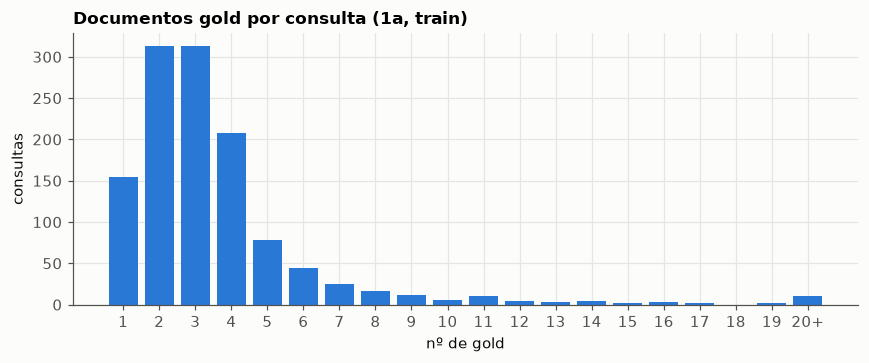

In [30]:
display(queries.groupby("domain")["n_gold"].describe()[["mean", "50%", "min", "max"]].round(1)
        .assign(pct_mas_de_10=queries.groupby("domain")["n_gold"].apply(lambda s: 100 * (s > 10).mean()).round(1)))

fig, ax = plt.subplots(figsize=(8, 3.4))
counts = queries["n_gold"].clip(upper=20).value_counts().sort_index()
ax.bar(counts.index, counts.values, color=C_GOLD, width=0.8)
ax.set_xticks(range(1, 21), [str(i) if i < 20 else "20+" for i in range(1, 21)])
style_ax(ax, "Documentos gold por consulta (1a, train)", "nº de gold", "consultas")
plt.tight_layout(); plt.show()

### 3.3 `gold_answers`

Las respuestas aceptadas de StackExchange **no estarán en test**, pero pueden servir para entrenar o como inspiración para generación de consultas sintéticas tipo HyDE. Se mide su longitud y lo cerca que están léxicamente de los gold comparado con la propia consulta.

In [31]:
display(queries.groupby("domain")[["n_answers", "words_answers"]].median().round(0))
print(f"Consultas sin gold_answers: {(queries['n_answers'] == 0).sum()} de {len(queries)}")

,n_answers,words_answers
domain,,
bitcoin,1.0,182.0
cardano,1.0,92.0
economics,1.0,317.0
genealogy,1.0,218.0
history,1.0,436.0
hsm,1.0,387.0
iota,1.0,190.0
law,1.0,280.0
monero,1.0,116.0


Consultas sin gold_answers: 0 de 1211


### 3.4 Expresiones temporales explícitas en la consulta

,año,fecha,década/siglo,relativa,recencia,rango,alguna
domain,,,,,,,
cardano,5.6,5.6,0.0,41.7,38.9,2.8,55.6
iota,0.0,0.0,0.0,42.9,57.1,0.0,57.1
bitcoin,18.6,7.1,0.0,54.3,37.1,0.0,65.7
quant,25.0,12.5,0.0,54.2,37.5,4.2,70.8
economics,44.8,5.2,8.6,51.7,27.6,6.9,74.1
monero,30.4,15.2,0.0,69.6,45.7,4.3,78.3
history,42.6,10.3,12.3,62.6,26.0,7.5,78.6
law,37.5,20.8,0.0,70.8,41.7,0.0,79.2
hsm,35.2,1.0,26.7,64.8,30.5,4.8,81.0


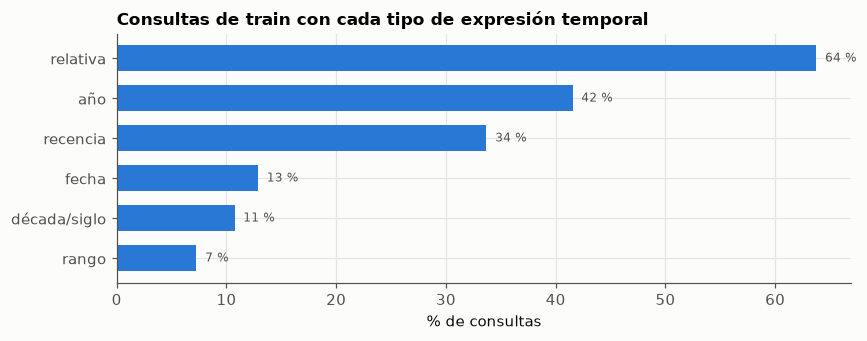

In [32]:
flags = pd.DataFrame([temporal_query_flags(t) for t in queries["clean"]], index=queries.index)
flags["alguna"] = flags.any(axis=1)
queries = pd.concat([queries.drop(columns=flags.columns, errors="ignore"), flags], axis=1)
tq = (100 * queries.groupby("domain")[list(flags.columns)].mean()).round(1).sort_values("alguna")
display(tq)

fig, ax = plt.subplots(figsize=(8, 3.2))
glob = (100 * flags.mean()).drop("alguna").sort_values()
ax.barh(glob.index, glob.values, color=C_GOLD, height=0.65)
for i, v in enumerate(glob.values):
    ax.text(v + 0.8, i, f"{v:.0f} %", va="center", fontsize=8, color=INK_MUTED)
style_ax(ax, "Consultas de train con cada tipo de expresión temporal", "% de consultas")
plt.tight_layout(); plt.show()

### 3.5 Solapamiento léxico consulta ↔ gold

Jaccard entre los conjuntos de términos analizados (Lucene: stems, sin stopwords) de la consulta limpia y de cada documento. Se compara con documentos **no-gold** de la muestra del mismo dominio (5 al azar por consulta) y con las `gold_answers`. (La posición del mejor gold en el ranking BM25 está en `baseline_track1_tempo.ipynb`.)

In [33]:
# Analizador de Lucene (Pyserini) para el Jaccard de 3.5; es el mismo que usa el baseline BM25.
_ANALYZER = None


def lucene_analyze(text: str) -> list[str]:
    """Tokeniza con el analizador de Lucene por defecto de Pyserini (inglés, Porter, sin stopwords).

    El analizador se crea una sola vez (arranca la JVM) y se reutiliza.

    Args:
        text: texto a analizar.

    Returns:
        Lista de términos analizados.
    """
    # Ejemplo: "The Bitcoin <b>halving</b> in 2020" -> ["bitcoin", "b", "halv", "b", "2020"]
    #   - pasa a minúsculas, parte por espacios/puntuación,
    #   - quita stopwords ("the", "in"...), y
    #   - aplica el stemmer de Porter ("halving" -> "halv"), para que "halving"/"halved" coincidan.
    # OJO: no limpia HTML, así que restos de etiquetas como "b" o "href" se cuelan como términos.
    global _ANALYZER
    if _ANALYZER is None:
        from pyserini import analysis
        _ANALYZER = analysis.Analyzer(analysis.get_lucene_analyzer())
    return _ANALYZER.analyze(text)


In [34]:
def jaccard(a: set, b: set) -> float:
    """Similitud de Jaccard entre dos conjuntos (0 si ambos están vacíos)."""
    return len(a & b) / len(a | b) if a or b else 0.0


rng = random.Random(SEED)
ov_rows = []
for dom in DOMAINS:
    texts = load_texts(dom)
    nongold_ids = stats.loc[(stats["domain"] == dom) & stats["in_sample"] & ~stats["gold_train"] & ~stats["gold_dev"], "id"].tolist()
    term_cache = {}

    def terms(doc_id):
        """Conjunto de términos analizados de un documento (con caché local)."""
        if doc_id not in term_cache:
            term_cache[doc_id] = set(lucene_analyze(texts[doc_id]))
        return term_cache[doc_id]

    for r in load_examples(dom):
        q = set(lucene_analyze(clean_query(r["query"])))
        ans = set(lucene_analyze(" ".join(BeautifulSoup(a, "html.parser").get_text(" ") for a in r["gold_answers"])))
        for g in r["gold_ids"]:
            ov_rows.append({"domain": dom, "qid": r["id"], "tipo": "consulta↔gold", "jaccard": jaccard(q, terms(g))})
            if ans:
                ov_rows.append({"domain": dom, "qid": r["id"], "tipo": "respuesta↔gold", "jaccard": jaccard(ans, terms(g))})
        for n in rng.sample(nongold_ids, min(5, len(nongold_ids))):
            ov_rows.append({"domain": dom, "qid": r["id"], "tipo": "consulta↔no-gold", "jaccard": jaccard(q, terms(n))})
overlap = pd.DataFrame(ov_rows)
# El notebook del baseline lo lee para la revisión de consultas fallidas.
overlap.to_parquet(CACHE_DIR / "overlap_jaccard.parquet", index=False)
display(overlap.groupby(["domain", "tipo"])["jaccard"].median().unstack().round(3))

tipo,consulta↔gold,consulta↔no-gold,respuesta↔gold
domain,,,
bitcoin,0.075,0.026,0.079
cardano,0.059,0.019,0.063
economics,0.069,0.026,0.091
genealogy,0.067,0.026,0.079
history,0.066,0.021,0.077
hsm,0.058,0.028,0.084
iota,0.034,0.025,0.069
law,0.089,0.027,0.085
monero,0.078,0.017,0.071


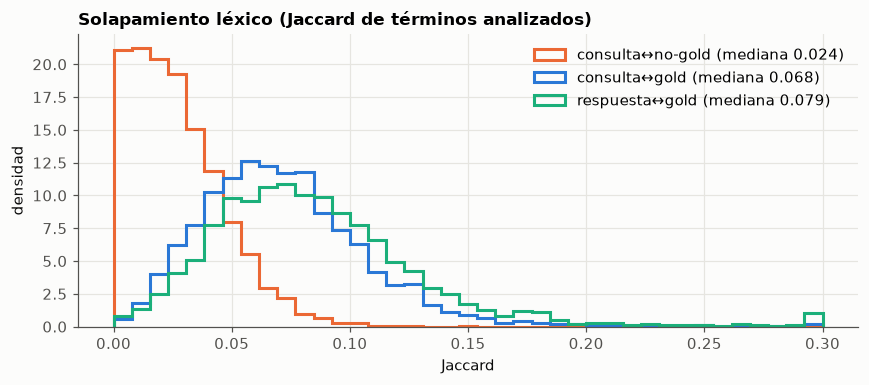

In [35]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(0, 0.3, 40)
for tipo, color in [("consulta↔no-gold", C_NOGOLD), ("consulta↔gold", C_GOLD), ("respuesta↔gold", C_THIRD)]:
    vals = overlap.loc[overlap["tipo"] == tipo, "jaccard"].clip(upper=0.3)
    ax.hist(vals, bins=bins, histtype="step", lw=2, color=color, density=True, label=f"{tipo} (mediana {vals.median():.3f})")
ax.legend()
style_ax(ax, "Solapamiento léxico (Jaccard de términos analizados)", "Jaccard", "densidad")
plt.tight_layout(); plt.show()

## 4. Pasos 1b (`steps_train.jsonl`)

### 4.1 Pasos por consulta y gold por paso

In [36]:
s_rows = []
for dom in DOMAINS:
    for r in load_steps(dom):
        for s in r["steps"]:
            instr = s["step_instruction"]
            s_rows.append({
                "domain": dom, "qid": r["id"], "step_id": s["step_id"], "step": s["step"],
                "n_steps_query": len(r["steps"]), "n_gold": len(s["gold_ids"]),
                "words": len(WORD_RE.findall(instr)), "first_word": instr.split()[0].strip(",.:").lower() if instr else "",
                "is_question": instr.strip().endswith("?"), "instruction": instr,
            })
steps = pd.DataFrame(s_rows)

per_query = steps.groupby(["domain", "qid"]).size()
display(pd.DataFrame({
    "registros": per_query.groupby("domain").size(),
    "pasos_por_registro_media": per_query.groupby("domain").mean().round(2),
    "gold_por_paso_media": steps.groupby("domain")["n_gold"].mean().round(2),
    "gold_por_paso_max": steps.groupby("domain")["n_gold"].max(),
    "palabras_instrucción_p50": steps.groupby("domain")["words"].median(),
}))

,registros,pasos_por_registro_media,gold_por_paso_media,gold_por_paso_max,palabras_instrucción_p50
domain,,,,,
bitcoin,61,2.16,1.54,4,14.0
cardano,28,2.04,1.26,2,14.0
economics,54,2.41,1.65,4,16.0
genealogy,71,2.24,1.38,4,16.0
history,538,2.64,1.64,6,17.0
hsm,102,2.49,1.33,4,17.0
iota,7,2.29,1.38,2,13.0
law,23,2.30,1.43,4,17.0
monero,34,2.15,1.34,4,14.0


### 4.2 Estilo de `step_instruction`

¿Son instrucciones imperativas ("Consult…", "Identify…") o preguntas? Las instrucciones contienen palabras como *consult*, *identify*, *documentation* que no están en los documentos y pueden meter ruido en un retriever léxico.

% de instrucciones que terminan en '?': 0.0 %
Las 15 primeras palabras más frecuentes cubren el 97.4 % de los pasos


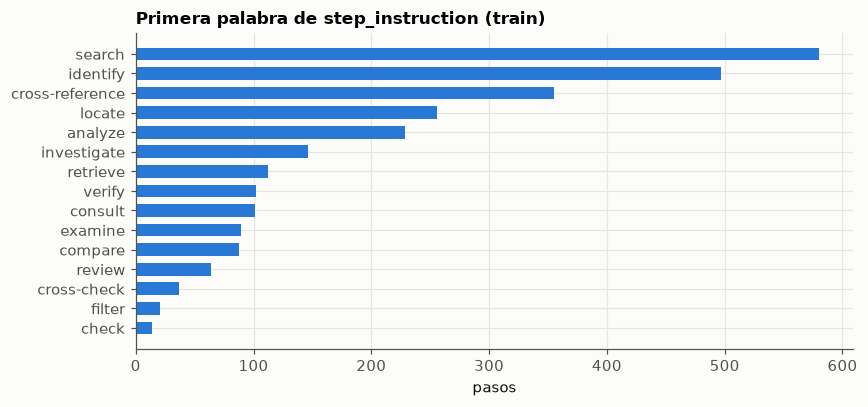

,domain,step,instruction
55,bitcoin,2,Analyze current mining profitability metrics and compare them with projections for April 2024 based on halving effects.
1889,history,4,Cross-reference findings with historical accounts to assess the scale and focus of prosecutions.
1934,hsm,4,"Cross-reference timelines of vacuum tube applications with broader historical events, such as radar development and ..."
1520,history,1,"Search for historical accounts, articles, and books documenting spiritualism trends after World War 1."
2567,quant,2,"Identify documentation or guidelines on handling timing discrepancies, such as Roll conventions and contractual paym..."
1201,history,2,"Identify references to anti-spall technology or materials (e.g., canvas, padding) in historical accounts or naval tr..."


In [37]:
fw = steps["first_word"].value_counts()
print(f"% de instrucciones que terminan en '?': {100 * steps['is_question'].mean():.1f} %")
print(f"Las 15 primeras palabras más frecuentes cubren el {100 * fw.head(15).sum() / fw.sum():.1f} % de los pasos")

fig, ax = plt.subplots(figsize=(8, 3.8))
top = fw.head(15)[::-1]
ax.barh(top.index, top.values, color=C_GOLD, height=0.65)
style_ax(ax, "Primera palabra de step_instruction (train)", "pasos")
plt.tight_layout(); plt.show()

display(steps.sample(6, random_state=SEED)[["domain", "step", "instruction"]])

### 4.3 Solapamiento de gold entre pasos y con 1a

In [38]:
ov_steps = []
for dom in DOMAINS:
    gold_1a = {r["id"]: set(r["gold_ids"]) for r in load_examples(dom)}
    for r in load_steps(dom):
        step_sets = [set(s["gold_ids"]) for s in r["steps"]]
        union = set().union(*step_sets)
        pair_j = [jaccard(a, b) for a, b in combinations(step_sets, 2)]
        ov_steps.append({
            "domain": dom, "qid": r["id"], "n_pasos": len(step_sets),
            "jaccard_entre_pasos": np.mean(pair_j) if pair_j else np.nan,
            "%gold_1b_en_1a": 100 * len(union & gold_1a[r["id"]]) / len(union) if union else np.nan,
            "%gold_1a_cubierto_por_1b": 100 * len(union & gold_1a[r["id"]]) / len(gold_1a[r["id"]]),
        })
ov_steps = pd.DataFrame(ov_steps)
display(ov_steps.groupby("domain")[["jaccard_entre_pasos", "%gold_1b_en_1a", "%gold_1a_cubierto_por_1b"]].mean().round(2))
print(f"Registros con un solo paso: {(ov_steps['n_pasos'] == 1).mean() * 100:.1f} %")

,jaccard_entre_pasos,%gold_1b_en_1a,%gold_1a_cubierto_por_1b
domain,,,
bitcoin,0.28,100.0,82.49
cardano,0.38,100.0,86.46
economics,0.32,100.0,81.39
genealogy,0.41,100.0,77.19
history,0.37,100.0,76.69
hsm,0.48,100.0,85.54
iota,0.21,100.0,67.14
law,0.31,100.0,82.25
monero,0.35,100.0,75.74


Registros con un solo paso: 16.6 %


### 4.4 Pasos "hueco": ¿qué se filtró?

Hipótesis: los pasos de `steps_*.jsonl` son las acciones del `retrieval_plan` de guidance que tienen `gold_ids` no vacíos. Se comprueba (a) que cada paso coincide en número y texto con una acción del plan, y (b) que las acciones del plan sin gold son exactamente los pasos que faltan.

In [39]:
hyp_rows = []
for dom in DOMAINS:
    guid = {g["id"]: g["query_guidance"]["retrieval_plan"] for g in load_guidance(dom)}
    steps_by_q = {r["id"]: {s["step"]: s for s in r["steps"]} for r in load_steps(dom)}
    for qid, plan in guid.items():
        present = steps_by_q.get(qid, {})
        with_gold = {a["step"] for a in plan if a["gold_ids"]}
        same_text = all(present[n]["step_instruction"] == a["action"] for a in plan for n in [a["step"]] if n in present)
        same_gold = all(set(present[n]["gold_ids"]) == set(a["gold_ids"]) for a in plan for n in [a["step"]] if n in present)
        hyp_rows.append({
            "domain": dom, "qid": qid, "acciones_plan": len(plan), "acciones_con_gold": len(with_gold),
            "pasos_presentes": len(present), "pasos=acciones_con_gold": set(present) == with_gold,
            "texto_igual": same_text, "gold_igual": same_gold,
        })
hyp = pd.DataFrame(hyp_rows)
display(hyp.groupby("domain").agg(
    consultas=("qid", "size"), acciones=("acciones_plan", "sum"), acciones_con_gold=("acciones_con_gold", "sum"),
    pasos=("pasos_presentes", "sum"), hipotesis_ok=("pasos=acciones_con_gold", "mean"),
    texto_igual=("texto_igual", "mean"), gold_igual=("gold_igual", "mean")).round(3))
print(f"Consultas de train sin ninguna acción con gold (y por tanto sin registro en steps): "
      f"{(hyp['acciones_con_gold'] == 0).sum()} de {len(hyp)}")

,consultas,acciones,acciones_con_gold,pasos,hipotesis_ok,texto_igual,gold_igual
domain,,,,,,,
bitcoin,70,209,132,132,1.0,1.0,1.0
cardano,36,101,57,57,1.0,1.0,1.0
economics,58,186,130,130,1.0,1.0,1.0
genealogy,80,299,159,159,1.0,1.0,1.0
history,561,1921,1421,1421,1.0,1.0,1.0
hsm,105,345,254,254,1.0,1.0,1.0
iota,7,22,16,16,1.0,1.0,1.0
law,24,78,53,53,1.0,1.0,1.0
monero,46,127,73,73,1.0,1.0,1.0


Consultas de train sin ninguna acción con gold (y por tanto sin registro en steps): 90 de 1211


## 5. Guidance temporal (`guidance_train.jsonl`)

Información muy rica, pero probablemente **no disponible en test** (pregunta abierta 1 del plan). Aquí se trata como señal de análisis y de entrenamiento (por ejemplo, para entrenar un clasificador de intención temporal o para generar datos sintéticos), no como input de inferencia.

### 5.1 Distribuciones de los metadatos de la consulta

In [40]:
g_rows, a_rows = [], []
for dom in DOMAINS:
    for g in load_guidance(dom):
        qg = g["query_guidance"]
        g_rows.append({
            "domain": dom, "qid": g["id"], "temporal_intent": qg["temporal_intent"],
            "clase_primaria": qg["temporal_reasoning_class_primary"],
            "clases_secundarias": qg["temporal_reasoning_class_secondary"],
            "granularidad": qg["expected_granularity"], "is_temporal_query": qg["is_temporal_query"],
            "anchors": qg["key_time_anchors"], "signals": qg["query_temporal_signals"],
            "n_plan": len(qg["retrieval_plan"]),
        })
        for a in g["gold_passage_annotations"]:
            a_rows.append({"domain": dom, "qid": g["id"], "doc_id": a["doc_id"], "tense": a["tense_guess"],
                           "granularidad_pasaje": a["time_scope_guess"].get("granularity", ""),
                           "start_iso": a["time_scope_guess"].get("start_iso", ""),
                           "end_iso": a["time_scope_guess"].get("end_iso", ""),
                           "confidence": a["confidence"], "n_time_mentions": len(a["time_mentions"]),
                           "time_mentions": a["time_mentions"], "signals": a["passage_temporal_signals"]})
guid = pd.DataFrame(g_rows)
annot = pd.DataFrame(a_rows)
# Las cadenas vacías se etiquetan explícitamente para que se vean en tablas y gráficos.
for col in ["temporal_intent", "clase_primaria", "granularidad"]:
    guid[col] = guid[col].replace("", "(vacío)")
# expected_granularity es texto libre (decenas de valores): los poco frecuentes se agrupan en "otras".
gran_counts = guid["granularidad"].value_counts()
guid["granularidad_top"] = guid["granularidad"].where(guid["granularidad"].map(gran_counts) >= 15, "otras")
print(f"expected_granularity tiene {gran_counts.size} valores distintos; los de <15 consultas se agrupan en 'otras'")

for col in ["temporal_intent", "clase_primaria", "granularidad_top", "is_temporal_query"]:
    vc = guid[col].value_counts()
    display(Markdown(f"**{col}** ({vc.size} valores)"))
    display((100 * vc / vc.sum()).round(1).to_frame("%").T)
sec = guid["clases_secundarias"].explode().value_counts()
display(Markdown("**clases secundarias** (una consulta puede tener varias)"))
display(sec.to_frame("consultas").T)

expected_granularity tiene 93 valores distintos; los de <15 consultas se agrupan en 'otras'


**temporal_intent** (18 valores)

temporal_intent,when,period_definition,timeline,ongoing_status,duration,none,before_after,order,origins_evolution_comparative_analysis,event_verification_and_authenticity,trends_changes_and_cross_period,after,historical_attribution_and_context,event_analysis_and_localization,causation_analysis,why,during,since
%,22.9,20.1,20.1,11.1,8.3,5.0,3.7,2.7,2.1,2.1,0.5,0.4,0.4,0.2,0.1,0.1,0.1,0.1


**clase_primaria** (13 valores)

clase_primaria,event_analysis_and_localization,time_period_contextualization,origins_evolution_comparative_analysis,trends_changes_and_cross_period,event_verification_and_authenticity,materials_artifacts_and_provenance,(vacío),causation_analysis,sources_methods_and_documentation,historical_attribution_and_context,none,historical_misinterpretation_or_reenactment,artifact_verification
%,35.9,21.1,14.1,9.7,6.6,5.6,3.0,1.2,1.2,1.2,0.1,0.1,0.1


**granularidad_top** (13 valores)

granularidad_top,year,otras,decade,century,date,period,month,(vacío),era,duration,hours,day,days
%,30.0,14.5,11.4,10.9,9.7,8.4,4.2,3.3,2.1,1.7,1.4,1.2,1.2


**is_temporal_query** (2 valores)

is_temporal_query,True,False
%,95.0,5.0


**clases secundarias** (una consulta puede tener varias)

clases_secundarias,origins_evolution_comparative_analysis,materials_artifacts_and_provenance,historical_attribution_and_context,sources_methods_and_documentation,trends_changes_and_cross_period,causation_analysis,time_period_contextualization,event_analysis_and_localization,event_verification_and_authenticity,historical_misinterpretation_or_reenactment,artifact_verification
consultas,255,191,188,158,157,140,112,33,10,4,1


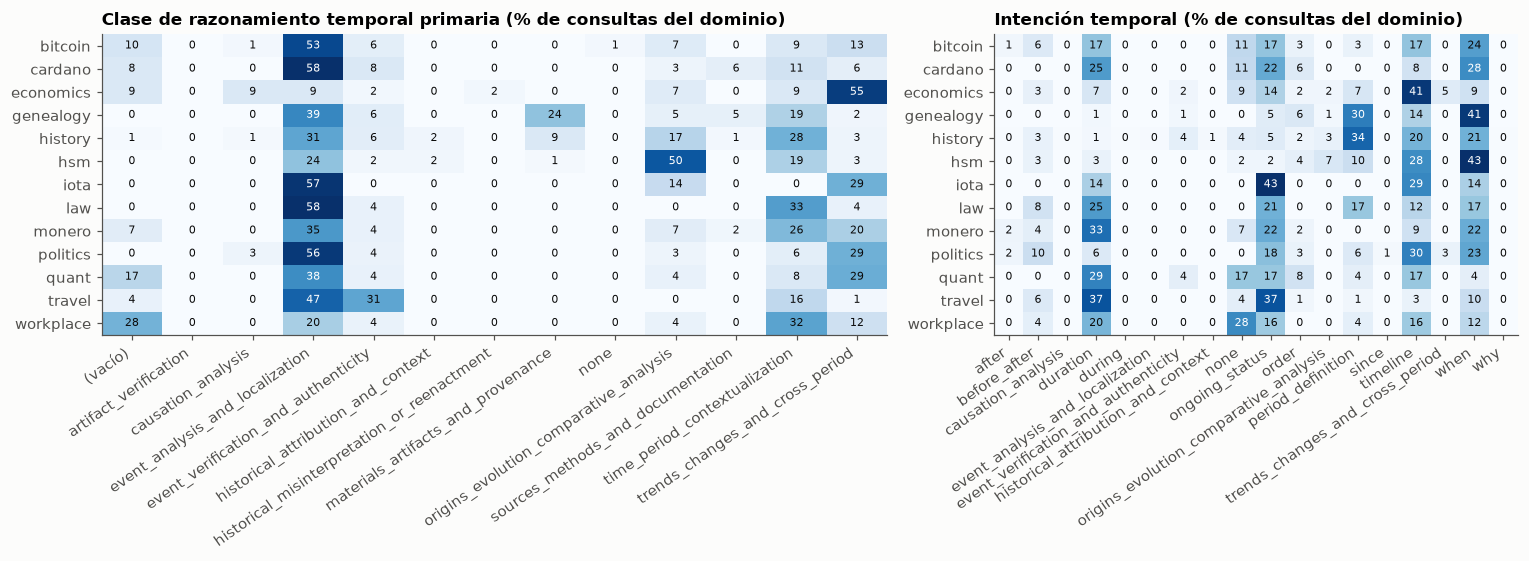

In [41]:
def heatmap(ax, table: pd.DataFrame, title: str, fmt: str = "{:.0f}") -> None:
    """Dibuja un mapa de calor secuencial (un solo tono) con los valores anotados.

    Args:
        ax: eje de matplotlib.
        table: tabla numérica (filas × columnas).
        title: título del gráfico.
        fmt: formato de los valores anotados.
    """
    im = ax.imshow(table.values, cmap="Blues", aspect="auto", vmin=0)
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=35, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.grid(False)
    vmax = np.nanmax(table.values)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                    color="white" if v > 0.6 * vmax else INK)
    style_ax(ax, title)


fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
heatmap(axes[0], 100 * pd.crosstab(guid["domain"], guid["clase_primaria"], normalize="index"),
        "Clase de razonamiento temporal primaria (% de consultas del dominio)")
heatmap(axes[1], 100 * pd.crosstab(guid["domain"], guid["temporal_intent"], normalize="index"),
        "Intención temporal (% de consultas del dominio)")
plt.tight_layout(); plt.show()

### 5.2 `retrieval_plan` vs. `steps`

Ya verificado en 4.4: aquí se resume cuántas acciones del plan tienen `gold_ids` vacíos (y, por lo tanto, no se convierten en pasos de 1b).

In [42]:
plan_summary = hyp.groupby("domain")[["acciones_plan", "acciones_con_gold"]].sum()
plan_summary["%acciones_sin_gold"] = (100 * (1 - plan_summary["acciones_con_gold"] / plan_summary["acciones_plan"])).round(1)
plan_summary = add_total_row(plan_summary.drop(columns="%acciones_sin_gold"))
plan_summary["%acciones_sin_gold"] = (100 * (1 - plan_summary["acciones_con_gold"] / plan_summary["acciones_plan"])).round(1)
display(plan_summary)

,acciones_plan,acciones_con_gold,%acciones_sin_gold
domain,,,
bitcoin,209,132,36.8
cardano,101,57,43.6
economics,186,130,30.1
genealogy,299,159,46.8
history,1921,1421,26.0
hsm,345,254,26.4
iota,22,16,27.3
law,78,53,32.1
monero,127,73,42.5


### 5.3 Anotaciones de los pasajes gold

Distribución de `tense_guess`, granularidad del `time_scope_guess`, `confidence` y número de `time_mentions`. Después, **coincidencia de anclas**: se extraen los años de `key_time_anchors` + `query_temporal_signals` (consulta) y de `time_mentions` + `passage_temporal_signals` + `start/end_iso` (pasaje gold) y se mira si comparten al menos un año.

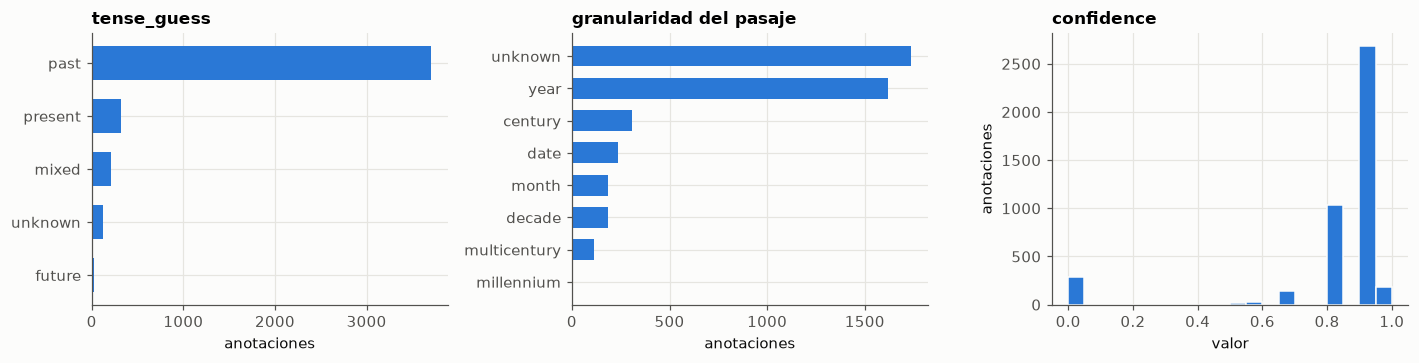

Anotaciones: 4,381 | sin time_mentions: 14.2 % | con start_iso: 58.3 %


In [43]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, title in [(axes[0], "tense", "tense_guess"), (axes[1], "granularidad_pasaje", "granularidad del pasaje")]:
    vc = annot[col].replace("", "(vacío)").value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color=C_GOLD, height=0.65)
    style_ax(ax, title, "anotaciones")
axes[2].hist(annot["confidence"], bins=20, color=C_GOLD, edgecolor="#fcfcfb")
style_ax(axes[2], "confidence", "valor", "anotaciones")
plt.tight_layout(); plt.show()

print(f"Anotaciones: {len(annot):,} | sin time_mentions: {100 * (annot['n_time_mentions'] == 0).mean():.1f} % | "
      f"con start_iso: {100 * (annot['start_iso'] != '').mean():.1f} %")

In [44]:
def years_in(items) -> set[str]:
    """Extrae los años (1500–2039) de una lista de cadenas o de una cadena."""
    if isinstance(items, str):
        items = [items]
    return {y for s in items for y in YEAR_RE.findall(str(s))}


q_years = guid.set_index("qid").apply(lambda r: years_in(list(r["anchors"]) + list(r["signals"])), axis=1)
annot["years_passage"] = annot.apply(
    lambda r: years_in(list(r["time_mentions"]) + list(r["signals"]) + [r["start_iso"], r["end_iso"]]), axis=1)
annot["years_query"] = annot["qid"].map(q_years)
both = annot[(annot["years_query"].str.len() > 0) & (annot["years_passage"].str.len() > 0)].copy()
both["comparte_año"] = [bool(a & b) for a, b in zip(both["years_query"], both["years_passage"])]

anchors = pd.DataFrame({
    "%consultas_con_año": 100 * guid.groupby("domain")["qid"].apply(lambda s: (s.map(q_years).str.len() > 0).mean()),
    "%pasajes_con_año": 100 * annot.groupby("domain")["years_passage"].apply(lambda s: (s.str.len() > 0).mean()),
    "%comparten_año (si ambos tienen)": 100 * both.groupby("domain")["comparte_año"].mean(),
    "pares_comparables": both.groupby("domain").size(),
}).round(1)
display(anchors)
print(f"Global: {100 * both['comparte_año'].mean():.1f} % de los pares (consulta, gold) con años en ambos lados comparten al menos uno")

,%consultas_con_año,%pasajes_con_año,%comparten_año (si ambos tienen),pares_comparables
domain,,,,
bitcoin,24.3,21.1,54.5,22.0
cardano,5.6,21.2,NaN,NaN
economics,48.3,63.5,43.0,79.0
genealogy,90.0,85.8,30.6,186.0
history,52.8,57.8,47.9,972.0
hsm,41.9,86.5,38.5,104.0
iota,0.0,31.0,NaN,NaN
law,37.5,46.8,31.6,19.0
monero,32.6,18.0,38.5,13.0


Global: 45.0 % de los pares (consulta, gold) con años en ambos lados comparten al menos uno


<!-- HALLAZGOS -->
## 6. Hallazgos sobre los datos

Todas las cifras son de **train** (salvo las comprobaciones de integridad de la sección 1, que cubren ambos splits). Los hallazgos que dependen de correr un retriever (BM25, densos, varianza) y las decisiones de pipeline están en `baseline_track1_tempo.ipynb`, sección 5.

### Datos y estructura
- **Los datos están limpios.** Todos los conteos coinciden con `split_manifest.json`, no hay solapamiento entre train y dev, todos los gold existen en el corpus, qrels y `gold_ids` coinciden par a par y ningún ID eliminado por la deduplicación aparece en los archivos de tareas. Los únicos campos vacíos están en guidance (p. ej., 36 consultas de train sin clase primaria y 23 sin `retrieval_plan`).
- **Los pasos de 1b son exactamente las acciones del `retrieval_plan` con `gold_ids` no vacíos** (100 % de coincidencia en número, texto y gold). El 30.6 % de las acciones del plan no tienen gold y por eso hay "huecos" en la numeración. 90 de 1,211 consultas de train (7.4 %) no tienen ningún paso.
- Los gold de 1b son siempre un subconjunto de los gold 1a de su consulta; la unión de los pasos cubre el 67–91 % de los gold 1a.

### Corpus
- **Mediana de ~150 palabras por documento, pero con cola larga:** el 9–18 % de los documentos supera 512 tokens de BGE (`history`: p90 = 1,095 tokens). **Decisión:** fragmentar (*chunking*) para los encoders, p. ej. ventanas de ~256–384 tokens con solapamiento, y agregar por documento con el máximo.
- El texto es casi todo texto plano, con algo de markdown (hasta un 11 %). Hay restos de MathML/LaTeX (`displaystyle`, `frac`, `span`), que son los términos más sobrerrepresentados en los gold. Además hay boilerplate (menús de idiomas, botones de compartir, estado JS). **Decisión:** normalizar markdown y fórmulas antes de indexar, sin eliminar documentos (ningún gold es boilerplate, pero tampoco hay garantía en test).
- **Casi-duplicados:** el 9–11 % de los documentos de los dominios pequeños está en algún par con Jaccard ≥ 0.8. Afectan a pocos gold, pero ocupan posiciones del top-10 con contenido repetido. **Decisión:** probar deduplicación difusa del ranking (MMR o colapso por firma MinHash) en el post-procesado.
- **⚠️ Leakage por ID.** Los 6,098 gold tienen ID corto (`<hash8>_<n>`). Los 781k documentos de ID largo (`<número>_<hash16>_<n>`, el 67 % del corpus y ninguno en `history`) **nunca** son gold, y su prefijo es el número de pregunta de las consultas de train y dev. Además, el 95 % de las consultas tienen gold con sufijos consecutivos. Con el formato del ID, el AUC para distinguir gold sube de 0.64 a 0.90. **Decisión:** no usar los IDs como rasgo ni filtrar por ellos (el test podría construirse de otra forma). Lo que sí es legítimo es usar en train los documentos largos de una consulta como *hard negatives* temáticos para entrenar.
- Los rasgos superficiales (longitud, densidad temporal) separan poco los gold (AUC 0.64) y su dirección cambia de un dominio a otro.

### Consultas y pasos
- **Las consultas son largas** (mediana de 127 palabras sin HTML, p90 = 321) y el HTML es el 4–21 % de los caracteres. **Decisión:** usar siempre consultas limpias y probar variantes título + resumen, o reformulaciones con un LLM.
- El 80 % de las consultas tiene alguna expresión temporal explícita (relativas en más del 60 %; años en el 90 % de `genealogy` y el 62 % de `politics`).
- **Hay un vacío léxico:** el Jaccard consulta↔gold es ~0.07 frente a ~0.025 con no-gold.
- `gold_answers` (siempre 1 por consulta) se parece al gold solo un poco más que la propia consulta. Sirve para entrenar o como modelo de "documento hipotético" (HyDE), pero no estará en test.

### Guidance temporal
- El 95 % de las consultas está marcada como temporal. Clase primaria dominante: `event_analysis_and_localization` (36 %); intenciones: `when` (23 %), `period_definition` y `timeline` (20 % cada una).
- **Las etiquetas son ruidosas:** `temporal_intent` contiene nombres de clase como valor, y `expected_granularity` es texto libre con decenas de valores. Para usarlas como objetivo de entrenamiento hay que normalizarlas.
- Solo el 45 % de los pares (consulta, gold) con años en ambos lados comparten algún año: el anclaje temporal explícito no basta como filtro duro.